# MN3101 Corporate Finance: Markowitz Portfolio Analysis

**Aim.** Build two Markowitz efficient frontiers from 15 stocks (8 tech, 7 non-tech) with no risk-free asset:

1. **No short sales:** each weight in [0, 1]
2. **Bounded short sales:** each weight in [−1, 1]

In both cases the weights sum to 1 and there are no other constraints. For each frontier I find the **Global Minimum Variance (GMV)** portfolio and the **maximum-Sharpe** portfolio.

**Data rules (from the brief)**
- Source: Yahoo Finance via `yfinance`, with prices adjusted for splits and dividends
- The price on the last trading day of each month, giving 121 month-ends from 30 Sep 2016 to 30 Sep 2026
- 120 monthly **simple** returns, covering the same months for every stock
- No currency conversion (all 15 tickers are US listings quoted in USD)
- Annualisation: mean × 12, sample SD × √12, covariance × 12

**Working conventions**
- One step per code cell, with a markdown cell before it (what and why) and after it (what to check).
- Calculations keep full floating-point precision. Rounding is used **only for display**.

## Step 1: Import libraries

**What this does.** Loads the Python packages the analysis needs and prints their versions so the results can be reproduced.

| Package | Used for |
|---|---|
| `yfinance` | downloading adjusted prices from Yahoo Finance |
| `pandas` | tables of prices and returns indexed by date |
| `numpy` | vector and matrix maths (portfolio mean, variance) |
| `scipy.optimize` | numerical optimisation for the constrained frontiers |
| `matplotlib` | plotting the frontiers |
| `openpyxl` | the engine pandas uses to write Excel (.xlsx) tables |

In [29]:
# --- Standard library ---
import sys                      # to report the Python version
from pathlib import Path        # file paths that work on any operating system
import warnings                 # to control warning messages

# --- Third-party libraries (installed in the project's .venv) ---
import numpy as np              # arrays, matrix algebra (w' * Sigma * w, etc.)
import pandas as pd             # DataFrames for prices / returns
import yfinance as yf           # Yahoo Finance data download
import scipy                    # imported so its version can be printed
from scipy.optimize import minimize   # SLSQP optimiser for constrained portfolios
import matplotlib                # imported so its version can be printed
import matplotlib.pyplot as plt  # charts
import openpyxl                  # Excel writer engine for pandas .to_excel()

# Display settings only. These change how numbers are SHOWN, never how they
# are stored or calculated: pandas keeps full float64 precision internally.
pd.set_option("display.precision", 6)
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

# Print versions so a marker can reproduce the exact environment
print(f"Python      {sys.version.split()[0]}")
for name, mod in [("numpy", np), ("pandas", pd), ("yfinance", yf), ("scipy", scipy),
                  ("matplotlib", matplotlib), ("openpyxl", openpyxl)]:
    print(f"{name:<11} {mod.__version__}")

Python      3.9.6
numpy       2.0.2
pandas      2.3.3
yfinance    1.2.0
scipy       1.13.1
matplotlib  3.9.4
openpyxl    3.1.5


**What to check in the output**
- The cell runs with **no `ModuleNotFoundError`**. If you see one, the notebook is not using the `.venv` kernel ("Python (MN3101 .venv)").
- Python should be **3.9.6**, and the versions should match `requirements.txt` (e.g. yfinance 1.2.0, pandas 2.3.3, numpy 2.0.2).

## Step 2: Configuration (CONFIG)

**What this does.** Puts every input from the brief in one place, so no later cell hard-codes a ticker, date or rate:
- **the stock table**: company, ticker, sector, country, plus a `group` column for the two blocks: **Tech/semiconductors** (first 8) and **Non-tech** (last 7). Later steps compare the two groups using this column.
- the sample window (30 Sep 2016 to 30 Sep 2026) and the expected counts (121 month-ends, 120 returns)
- the annualisation factor (12), the two weight bounds, the two comparison pairs and the risk-free rate
- the output folders

**Notes**
- *Sector* is the stock's GICS sector. Alphabet and Meta are GICS **Communication Services** but are in the **Tech/semiconductors** group here, so `sector` and `group` are deliberately different columns.
- *Country* is where the company is headquartered. TSM (Taiwan) and ASML (Netherlands) are US listings quoted in USD, which is why no currency conversion is needed (Step 3 checks this).
- **Pairs.** `PAIR_CLOSE` (ASML, LRCX): both sell chip-making equipment into the same fab-capex cycle, so I expect a high correlation. `PAIR_LOOSE` (NVDA, WMT): AI/data-centre growth vs defensive grocery retail, so I expect a low correlation.
- `RF_ANNUAL` is used only to compute and rank Sharpe ratios. It is **not** an investable asset, so each frontier uses only the 15 stocks.

In [30]:
# ---------- Stock universe: exactly 15 stocks in two blocks ----------
# Columns: company, Yahoo ticker, GICS sector, country of headquarters, group (block)
CONFIG = pd.DataFrame(
    [
        # --- Block 1: Tech/semiconductors (8) ---
        ("Alphabet",                    "GOOGL", "Communication Services", "United States", "Tech/semiconductors"),
        ("Meta Platforms",              "META",  "Communication Services", "United States", "Tech/semiconductors"),
        ("Apple",                       "AAPL",  "Information Technology", "United States", "Tech/semiconductors"),
        ("NVIDIA",                      "NVDA",  "Information Technology", "United States", "Tech/semiconductors"),
        ("Taiwan Semiconductor (ADR)",  "TSM",   "Information Technology", "Taiwan",        "Tech/semiconductors"),
        ("ASML Holding (US listing)",   "ASML",  "Information Technology", "Netherlands",   "Tech/semiconductors"),
        ("Micron Technology",           "MU",    "Information Technology", "United States", "Tech/semiconductors"),
        ("Lam Research",                "LRCX",  "Information Technology", "United States", "Tech/semiconductors"),
        # --- Block 2: Non-tech (7) ---
        ("ExxonMobil",                  "XOM",   "Energy",                 "United States", "Non-tech"),
        ("Newmont",                     "NEM",   "Materials",              "United States", "Non-tech"),
        ("Walmart",                     "WMT",   "Consumer Staples",       "United States", "Non-tech"),
        ("Johnson & Johnson",           "JNJ",   "Health Care",            "United States", "Non-tech"),
        ("NextEra Energy",              "NEE",   "Utilities",              "United States", "Non-tech"),
        ("JPMorgan Chase",              "JPM",   "Financials",             "United States", "Non-tech"),
        ("Coca-Cola",                   "KO",    "Consumer Staples",       "United States", "Non-tech"),
    ],
    columns=["company", "ticker", "sector", "country", "group"],
)

GROUP_TECH, GROUP_NONTECH = "Tech/semiconductors", "Non-tech"
TICKERS         = CONFIG["ticker"].tolist()                                     # order used in every later table
TICKERS_TECH    = CONFIG.loc[CONFIG["group"] == GROUP_TECH, "ticker"].tolist()
TICKERS_NONTECH = CONFIG.loc[CONFIG["group"] == GROUP_NONTECH, "ticker"].tolist()

# ---------- Sample window ----------
START_MONTH_END = pd.Timestamp("2016-09-30")   # first month-end price (base for the first return)
END_MONTH_END   = pd.Timestamp("2026-09-30")   # last month-end price
N_PRICES_EXPECTED  = 121                       # month-end prices: Sep-2016 ... Sep-2026
N_RETURNS_EXPECTED = 120                       # monthly simple returns: Oct-2016 ... Sep-2026

# ---------- Annualisation (from the brief) ----------
PERIODS_PER_YEAR = 12   # mean x 12, covariance x 12, sample SD x sqrt(12)

# ---------- Frontier weight bounds (weights always sum to 1) ----------
BOUNDS_NO_SHORT      = (0.0, 1.0)    # no short sales
BOUNDS_BOUNDED_SHORT = (-1.0, 1.0)   # bounded short sales

# ---------- Pairs for the two-asset comparison ----------
PAIR_CLOSE = ("ASML", "LRCX")   # both sell chip-making equipment into the same fab-capex cycle
PAIR_LOOSE = ("NVDA", "WMT")    # AI/data-centre growth vs. defensive grocery retail

# ---------- Risk-free rate (used only to compute Sharpe ratios) ----------
RF_ANNUAL = 0.0421  # 3m US T-Bill (BEY), S&P Capital IQ, as of 3 Nov 2026

# ---------- Output folders ----------
PROJECT_DIR = Path.cwd()
DATA_DIR    = PROJECT_DIR / "data"
TABLES_DIR  = PROJECT_DIR / "outputs" / "tables"
FIGURES_DIR = PROJECT_DIR / "outputs" / "figures"
for folder in (DATA_DIR, TABLES_DIR, FIGURES_DIR):
    folder.mkdir(parents=True, exist_ok=True)   # creates the folder only if it is missing

# ---------- Sanity checks: stop immediately if CONFIG breaks the brief ----------
assert len(TICKERS) == 15, "Brief requires exactly 15 stocks"
assert len(set(TICKERS)) == 15, "Duplicate ticker in CONFIG"
assert TICKERS_TECH == TICKERS[:8] and TICKERS_NONTECH == TICKERS[8:], "Blocks must be first 8 / last 7"
assert all(t in TICKERS for t in PAIR_CLOSE + PAIR_LOOSE), "Pair ticker not in the universe"

# ---------- Show the configuration ----------
print(f"Stocks: {len(TICKERS)}  ({GROUP_TECH} {len(TICKERS_TECH)}, {GROUP_NONTECH} {len(TICKERS_NONTECH)})")
print(f"Window: {START_MONTH_END.date()} to {END_MONTH_END.date()}  "
      f"-> expect {N_PRICES_EXPECTED} month-end prices, {N_RETURNS_EXPECTED} returns")
print(f"RF_ANNUAL = {RF_ANNUAL}   PAIR_CLOSE = {PAIR_CLOSE}   PAIR_LOOSE = {PAIR_LOOSE}")
CONFIG.set_index(["group", "ticker"])   # two-level index shows the two blocks

Stocks: 15  (Tech/semiconductors 8, Non-tech 7)
Window: 2016-09-30 to 2026-09-30  -> expect 121 month-end prices, 120 returns
RF_ANNUAL = 0.0421   PAIR_CLOSE = ('ASML', 'LRCX')   PAIR_LOOSE = ('NVDA', 'WMT')


company                  sector        country
group               ticker                                                                   
Tech/semiconductors GOOGL                     Alphabet  Communication Services  United States
                    META                Meta Platforms  Communication Services  United States
                    AAPL                         Apple  Information Technology  United States
                    NVDA                        NVIDIA  Information Technology  United States
                    TSM     Taiwan Semiconductor (ADR)  Information Technology         Taiwan
                    ASML     ASML Holding (US listing)  Information Technology    Netherlands
                    MU               Micron Technology  Information Technology  United States
                    LRCX                  Lam Research  Information Technology  United States
Non-tech            XOM                     ExxonMobil                  Energy  United States
                    NEM                        Newmont               Materials  United States
                    WMT                        Walmart        Consumer Staples  United States
                    JNJ              Johnson & Johnson             Health Care  United States
                    NEE                 NextEra Energy               Utilities  United States
                    JPM                 JPMorgan Chase              Financials  United States
                    KO                       Coca-Cola        Consumer Staples  United States

**What to check in the output**
- **Stocks: 15 (Tech/semiconductors 8, Non-tech 7)**, with no `AssertionError`.
- The table is split into two blocks: Tech/semiconductors (GOOGL to LRCX), then Non-tech (XOM to KO).
- Window **2016-09-30 to 2026-09-30**, expecting **121** prices and **120** returns.
- `RF_ANNUAL = 0.0421`, and the pairs are **('ASML', 'LRCX')** and **('NVDA', 'WMT')**.

## Step 3: Check each ticker on Yahoo Finance

**What this does.** Asks Yahoo Finance about each ticker *before* downloading any prices, to confirm that:
1. the ticker **exists** and is an ordinary share (`quoteType = EQUITY`)
2. it trades on a **US exchange** in **USD**, so no currency conversion is needed (a brief requirement)
3. it was listed **before 30 Sep 2016**, so no stock is a recent IPO with missing history

`fast_info` gives the exchange and currency. `.info` gives Yahoo's company name, security type and first trade date.

**Automatic flags** (`FLAG`) break a rule and must be fixed. **Notes** (`note`) are known features of a listing that are acceptable but worth stating in the write-up:
- **GOOGL** is the Class A (voting) share. GOOG is Class C (non-voting). Both trade at almost identical prices.
- **META** traded as `FB` until June 2022. Yahoo keeps the full history under `META`.
- **TSM** is an ADR (1 ADR = 5 ordinary shares). Its home listing is `2330.TW`, priced in TWD.
- **ASML** is the New York registry share on Nasdaq. Its home listing is `ASML.AS`, priced in EUR.
- **WMT** moved its listing from NYSE to Nasdaq in December 2025. It is the same share, so the price history is unaffected.

Using the US listings of TSM and ASML is deliberate: it keeps all 15 stocks in USD, as the brief's "no currency conversion" rule requires.

In [31]:
US_EXCHANGES = {"NMS", "NGM", "NCM", "NYQ", "ASE", "PCX", "BTS"}   # Yahoo codes: Nasdaq tiers, NYSE, NYSE American, NYSE Arca, Cboe BZX

# Hand-written context for listings that are fine but need explaining (see markdown above)
LISTING_NOTES = {
    "GOOGL": "Class A (voting); GOOG = Class C",
    "META":  "ticker was FB until Jun-2022",
    "TSM":   "ADR (1 ADR = 5 shares); home = 2330.TW in TWD",
    "ASML":  "NY registry share; home = ASML.AS in EUR",
    "WMT":   "moved NYSE -> Nasdaq Dec-2025",
}

rows = []
for t in TICKERS:
    try:
        tk   = yf.Ticker(t)
        fast = tk.fast_info          # lightweight quote data: exchange, currency
        info = tk.info               # fuller profile: name, security type, first trade date
        exchange, currency = fast.exchange, fast.currency
        first_ms = info.get("firstTradeDateMilliseconds")
        first_trade = pd.to_datetime(first_ms, unit="ms").normalize() if first_ms else pd.NaT
        row = {"ticker": t, "yahoo_name": info.get("longName"), "quote_type": info.get("quoteType"),
               "exchange": exchange, "exchange_name": info.get("fullExchangeName"),
               "currency": currency, "first_trade": first_trade}
    except Exception as e:           # ticker not found or Yahoo unreachable
        row = {"ticker": t, "yahoo_name": None, "quote_type": None, "exchange": None,
               "exchange_name": None, "currency": None, "first_trade": pd.NaT, "error": str(e)}

    # ---- Automatic flags: anything here breaks a rule in the brief ----
    flags = []
    if row["yahoo_name"] is None:                     flags.append("NOT FOUND on Yahoo")
    if row["quote_type"] not in (None, "EQUITY"):     flags.append(f"not an equity ({row['quote_type']})")
    if row["currency"] not in (None, "USD"):          flags.append(f"currency {row['currency']} (needs conversion)")
    if row["exchange"] not in (None, *US_EXCHANGES):  flags.append(f"non-US exchange {row['exchange']}")
    if pd.isna(row["first_trade"]):                   flags.append("first trade date unknown")
    elif row["first_trade"] > START_MONTH_END:        flags.append("listed after 30-Sep-2016 (recent IPO)")
    row["FLAG"] = "; ".join(flags) if flags else "OK"
    row["note"] = LISTING_NOTES.get(t, "")
    rows.append(row)

ticker_check = (pd.DataFrame(rows).set_index("ticker")
                  [["yahoo_name", "quote_type", "exchange", "exchange_name", "currency", "first_trade", "FLAG", "note"]])

n_flagged = (ticker_check["FLAG"] != "OK").sum()
print(f"{len(ticker_check) - n_flagged} of {len(ticker_check)} tickers pass every check; {n_flagged} flagged")
ticker_check.to_csv(TABLES_DIR / "step03_ticker_check.csv")   # saved for the appendix
ticker_check

15 of 15 tickers pass every check; 0 flagged


,yahoo_name,quote_type,exchange,exchange_name,currency,first_trade,FLAG,note
ticker,,,,,,,,
GOOGL,Alphabet Inc.,EQUITY,NMS,NasdaqGS,USD,2004-08-19,OK,Class A (voting); GOOG = Class C
META,"Meta Platforms, Inc.",EQUITY,NMS,NasdaqGS,USD,2012-05-18,OK,ticker was FB until Jun-2022
AAPL,Apple Inc.,EQUITY,NMS,NasdaqGS,USD,1980-12-12,OK,
NVDA,NVIDIA Corporation,EQUITY,NMS,NasdaqGS,USD,1999-01-22,OK,
TSM,Taiwan Semiconductor Manufacturing Company Lim...,EQUITY,NYQ,NYSE,USD,1997-10-09,OK,ADR (1 ADR = 5 shares); home = 2330.TW in TWD
ASML,ASML Holding N.V.,EQUITY,NMS,NasdaqGS,USD,1995-03-15,OK,NY registry share; home = ASML.AS in EUR
MU,"Micron Technology, Inc.",EQUITY,NMS,NasdaqGS,USD,1984-06-01,OK,
LRCX,Lam Research Corporation,EQUITY,NMS,NasdaqGS,USD,1984-05-04,OK,
XOM,ExxonMobil Holdings Corporation,EQUITY,NYQ,NYSE,USD,1962-01-02,OK,


**What to check in the output**
- The first line should read **15 of 15 tickers pass every check; 0 flagged**. If anything is flagged, stop and fix it in CONFIG before downloading prices.
- `currency` is **USD** for all 15 rows, and `exchange` is NMS (NasdaqGS) or NYQ (NYSE).
- `first_trade` is before 2016-09-30 for every stock. The most recent listing is META (2012), so none is a recent IPO.
- Compare `yahoo_name` with the company names in CONFIG. They should describe the same company, for example "NVIDIA Corporation" for NVIDIA.
- **ExxonMobil:** Yahoo currently gives the name as *"ExxonMobil Holdings Corporation"* rather than *"Exxon Mobil Corporation"*. That suggests a holding-company reorganisation under the same `XOM` ticker. The step that builds month-end prices should confirm that XOM's price series is continuous, with no gap or jump at the changeover.
- The table is saved to `outputs/tables/step03_ticker_check.csv`.

## Step 4: Download daily adjusted prices (or reuse the saved download)

**What this does.** Gets **daily** prices for all 15 tickers from Yahoo Finance.

- `auto_adjust=True` means the `Close` column is the **adjusted close**: past prices are scaled down for every later split and dividend. A month-to-month change in this price is therefore the **total return** (price change plus reinvested dividends), which is the return Markowitz analysis needs.
- **Date range: 1 Aug 2016 to 1 Oct 2026.** Starting in August makes sure the whole of September 2016 is included, so its last trading day (30 Sep 2016) is there. yfinance's `end` date is **exclusive**, so `end="2026-10-01"` makes 30 Sep 2026 the last day downloaded.
- **Download time.** Yahoo recalculates adjusted prices every time a new dividend is paid, so the same history downloaded later can differ slightly. The download time is saved to `data/download_timestamp.txt` so the report can state it.

**The `REDOWNLOAD` switch (keeps the data fixed)**

| `REDOWNLOAD` | Saved files exist? | What happens |
|---|---|---|
| `False` (default) | yes | **Reuses** `data/raw_daily_prices.csv` and the original download time. No call to Yahoo. **Run All** gives exactly the same numbers every time. |
| `False` | no | Downloads fresh data and saves it (first run only). |
| `True` | either | Downloads fresh data and **overwrites** the saved files and the download time. Only do this on purpose. |

The saved CSV is read with `float_precision="round_trip"`, so the reused prices are bit-for-bit identical to the original download.

In [32]:
from datetime import datetime, timezone

REDOWNLOAD = False   # False = reuse the saved download (fixed data + fixed timestamp); True = fetch again from Yahoo

DOWNLOAD_START = "2016-08-01"   # a month before the first month-end, so all of Sep-2016 is included
DOWNLOAD_END   = "2026-10-01"   # yfinance's end date is EXCLUSIVE: the last day returned is 30-Sep-2026
RAW_CSV   = DATA_DIR / "raw_daily_prices.csv"
STAMP_TXT = DATA_DIR / "download_timestamp.txt"

if RAW_CSV.exists() and STAMP_TXT.exists() and not REDOWNLOAD:
    # ---- Reuse the saved download: no internet call, so the data and timestamp never change ----
    raw_daily = pd.read_csv(RAW_CSV, header=[0, 1], index_col=0, parse_dates=True,
                            float_precision="round_trip")    # exact read of every price
    stamp_text = STAMP_TXT.read_text()
    source_msg = "REUSED saved download (set REDOWNLOAD = True to fetch fresh data)"
else:
    # ---- Fresh download from Yahoo Finance ----
    download_time_utc = datetime.now(timezone.utc)          # adjusted prices change when new dividends are paid
    raw_daily = yf.download(
        TICKERS,
        start=DOWNLOAD_START,
        end=DOWNLOAD_END,
        interval="1d",        # DAILY bars; month-ends are built from these in Step 5
        auto_adjust=True,     # Close = price adjusted for splits AND dividends
        actions=False,        # no separate dividend/split columns needed (already in the adjusted Close)
        progress=False,       # no progress bar in the notebook output
    )
    if raw_daily.index.tz is not None:                      # drop any timezone so dates compare cleanly
        raw_daily.index = raw_daily.index.tz_localize(None)
    raw_daily.index.name = "date"
    stamp_text = (f"Yahoo Finance via yfinance {yf.__version__}, auto_adjust=True, interval=1d, "
                  f"start={DOWNLOAD_START}, end={DOWNLOAD_END} (exclusive)\n"
                  f"Downloaded (UTC):   {download_time_utc:%Y-%m-%d %H:%M:%S %Z}\n"
                  f"Downloaded (local): {download_time_utc.astimezone():%Y-%m-%d %H:%M:%S %Z}\n")
    raw_daily.to_csv(RAW_CSV)          # raw download, all fields (two header rows: field, ticker)
    STAMP_TXT.write_text(stamp_text)
    source_msg = "NEW download from Yahoo Finance - saved to data/raw_daily_prices.csv and data/download_timestamp.txt"

# Keep the adjusted Close only, with columns in CONFIG order
missing = [t for t in TICKERS if t not in raw_daily["Close"].columns or raw_daily["Close"][t].isna().all()]
if missing:
    raise RuntimeError(f"STOP: no data for {missing}. Replace these tickers in CONFIG.")
daily_close = raw_daily["Close"][TICKERS]

print(source_msg)
print(stamp_text)
print(f"Daily rows: {len(daily_close)}  |  first date {daily_close.index.min().date()}  |  "
      f"last date {daily_close.index.max().date()}  |  stocks {daily_close.shape[1]}")
daily_close.tail(3)

REUSED saved download (set REDOWNLOAD = True to fetch fresh data)
Yahoo Finance via yfinance 1.2.0, auto_adjust=True, interval=1d, start=2016-08-01, end=2026-10-01 (exclusive)
Downloaded (UTC):   2026-11-04 11:32:29 UTC
Downloaded (local): 2026-11-04 11:32:29 GMT

Daily rows: 2556  |  first date 2016-08-01  |  last date 2026-09-30  |  stocks 15


Ticker,GOOGL,META,AAPL,NVDA,TSM,ASML,MU,LRCX,XOM,NEM,WMT,JNJ,NEE,JPM,KO
date,,,,,,,,,,,,,,,
2026-09-28,342.750000,715.619995,338.399994,228.860001,452.880005,1769.076172,1053.814087,314.470001,162.520004,116.050003,108.730003,271.950012,75.489998,334.919098,87.180000
2026-09-29,340.920013,738.789978,329.399994,227.210007,456.940002,1831.973145,1064.912354,323.859985,161.350006,117.089996,106.800003,267.570007,75.889999,333.317108,86.839996
2026-09-30,344.079987,725.179993,333.019989,228.380005,456.190002,1809.283203,1064.942383,328.510010,162.750000,115.339996,103.919998,264.739990,75.739998,329.187683,86.080002


**What to check in the output**
- The first line says **REUSED saved download**. If it says **NEW download**, the data and timestamp have just been replaced.
- **The download time. Copy it into your report's data section**, e.g. *"Adjusted prices downloaded from Yahoo Finance on 4 Nov 2026 at 11:32 UTC."* It stays the same on every Run All while `REDOWNLOAD = False`.
- First date **2016-08-01** and last date **2026-09-30**, with **15** stocks and **2,556 daily rows**.
- The `tail(3)` table shows prices for late September 2026 with no blanks.

## Step 5: Convert to month-end prices (last trading day of each month)

**What this does.** `resample("ME").last()` groups the daily prices by calendar month and keeps the **last available price in each month**, which is the close on the month's last trading day. The result is labelled by the calendar month-end (e.g. `2017-12-31`), even when the last trading day was earlier (29 Dec 2017). The cell keeps exactly the 121 month-ends from 30 Sep 2016 to 30 Sep 2026.

It also records **which day** each price actually comes from (`last_trade_dates`), so Step 6 can check that every stock's price is from the same day.

**Why not download `interval="1mo"` directly?** Yahoo's monthly bars cause three problems:
1. **Labelled by the first of the month.** The bar for September 2016 is dated `2016-09-01`, but its close is the 30 Sep price. That is easy to misread as the August month-end, which would shift every return by one month. Shifted dates would also misalign the returns with the risk-free rate or any other dated data.
2. **No control over the day used.** With monthly bars you cannot see or verify which trading day's price Yahoo used. Building month-ends from daily data makes that choice explicit and checkable.
3. **The last bar can be a partial month.** Yahoo's current monthly bar is updated live (month to date), and its monthly series has occasionally shown duplicated or oddly dated rows around dividend dates. The daily series is the cleanest source.

So daily data plus `resample("ME").last()` gives *exactly* the brief's definition, the last trading-day price of each month, on dates that can be checked.

In [33]:
# 1) Month-end price = last available daily adjusted close in each calendar month
monthly_all = daily_close.resample("ME").last()

# 2) The actual trading date behind each month-end price (per stock):
#    replace each price with its own date (NaT where the price is missing), then take the last date per month
price_dates = pd.DataFrame(
    {t: daily_close.index.where(daily_close[t].notna()) for t in TICKERS}, index=daily_close.index
)
last_trade_dates_all = price_dates.resample("ME").last()

# 3) Keep exactly the 121 month-ends in the brief (30-Sep-2016 ... 30-Sep-2026)
EXPECTED_MONTH_ENDS = pd.date_range(START_MONTH_END, END_MONTH_END, freq="ME")   # the target calendar
monthly_prices   = monthly_all.reindex(EXPECTED_MONTH_ENDS)            # reindex, NOT fill: a missing month stays NaN
last_trade_dates = last_trade_dates_all.reindex(EXPECTED_MONTH_ENDS)
monthly_prices.index.name = last_trade_dates.index.name = "month_end"

print(f"Month-ends kept: {len(monthly_prices)}  ({monthly_prices.index[0].date()} to {monthly_prices.index[-1].date()})")
print(f"Daily months available before trimming: {len(monthly_all)} ({monthly_all.index[0].date()} to {monthly_all.index[-1].date()})")
monthly_prices.iloc[[0, 1, 2, -3, -2, -1]]   # first and last three month-ends, for a quick look

Month-ends kept: 121  (2016-09-30 to 2026-09-30)
Daily months available before trimming: 122 (2016-08-31 to 2026-09-30)


Ticker,GOOGL,META,AAPL,NVDA,TSM,ASML,MU,LRCX,XOM,NEM,WMT,JNJ,NEE,JPM,KO
month_end,,,,,,,,,,,,,,,
2016-09-30,39.824039,127.053139,25.852913,1.680991,24.254644,99.668358,17.335217,8.289947,56.663082,30.703585,20.342245,90.005424,23.681257,50.948196,31.039688
2016-10-31,40.113293,129.747299,25.964964,1.745758,24.659025,96.066536,16.730721,8.478135,54.092228,28.945311,19.749924,88.374939,24.780914,53.376228,31.098379
2016-11-30,38.428329,117.296562,25.404093,2.265315,23.541044,93.801765,19.041431,9.279909,57.177929,25.350576,19.865562,85.387535,22.284573,61.784187,29.844986
2026-07-31,355.901245,556.270996,308.643829,200.525620,403.168427,1626.853760,822.900513,292.709045,154.439987,93.515335,110.934418,255.091904,86.271248,350.043671,87.070435
2026-08-31,339.132019,571.888672,316.850006,220.533234,414.208801,1693.775513,958.579102,301.170044,160.949997,125.798126,104.870003,265.850006,82.339996,354.252655,88.144028
2026-09-30,344.079987,725.179993,333.019989,228.380005,456.190002,1809.283203,1064.942383,328.510010,162.750000,115.339996,103.919998,264.739990,75.739998,329.187683,86.080002


**What to check in the output**
- **Month-ends kept: 121**, from **2016-09-30 to 2026-09-30**.
- Before trimming there are **122** months (Aug 2016 to Sep 2026). Step 5 drops August 2016 and nothing else.
- The first and last rows show a price for every stock. These are **adjusted** prices, so early values (e.g. NVDA in 2016) are much lower than the prices quoted at the time, because of later splits.
- `reindex` is used instead of filling: if a month were missing it would appear as a blank (NaN) and Step 6 would catch it. Nothing is forward-filled or interpolated.

## Step 6: Data-quality checks (stop if any stock fails)

**What this does.** Tests the 121 × 15 month-end table against the brief before any returns are calculated. **If any stock fails, the cell raises an error and stops the notebook**, so that stock can be replaced. Nothing is forward-filled or interpolated.

| Check | Pass condition |
|---|---|
| Non-missing prices per stock | exactly **121** |
| NaNs | **0** in the whole table |
| Calendar gaps | the 121 month-ends are consecutive (no month skipped) |
| Same trading day | each stock's price comes from the **same last trading day** as every other stock in that month (if a stock stopped trading early, `.last()` would quietly pick an older price, so this catches it) |
| Positive prices | all prices > 0 |
| First / last date | first month-end 2016-09-30, last 2026-09-30 for every stock |

The cell also shows the **largest single-day price move** for each stock. This is for information only: it is a quick way to spot a broken series, such as the XOM holding-company change, which would show up as an unexplained jump.

In [34]:
# Market-wide last trading day of each month = latest date on which ANY stock traded that month
market_last_day = last_trade_dates.max(axis=1)

# Biggest one-day move per stock (information only, to spot a broken series)
daily_moves = daily_close.pct_change(fill_method=None).abs()

checks = pd.DataFrame({
    "n_prices":         monthly_prices.notna().sum(),                       # should be 121
    "n_NaN":            monthly_prices.isna().sum(),                        # should be 0
    "first_month_end":  monthly_prices.apply(lambda s: s.first_valid_index()),
    "last_month_end":   monthly_prices.apply(lambda s: s.last_valid_index()),
    "months_off_market_last_day": last_trade_dates.ne(market_last_day, axis=0).sum(),  # should be 0
    "min_price":        monthly_prices.min(),                               # should be > 0
    "max_daily_move":   daily_moves.max(),
    "max_move_date":    daily_moves.idxmax(),
})

# Whole-table test for skipped months: every gap between month-ends must be exactly one calendar month
months_apart = monthly_prices.index.to_period("M").astype("int64").to_series().diff().dropna()
no_calendar_gaps = bool((months_apart == 1).all())

# Pass/fail per stock
checks["PASS"] = (
    (checks["n_prices"] == N_PRICES_EXPECTED)
    & (checks["n_NaN"] == 0)
    & (checks["first_month_end"] == START_MONTH_END)
    & (checks["last_month_end"] == END_MONTH_END)
    & (checks["months_off_market_last_day"] == 0)
    & (checks["min_price"] > 0)
)

print(f"Table shape: {monthly_prices.shape}  (expect ({N_PRICES_EXPECTED}, {len(TICKERS)}))")
print(f"Total NaNs in table: {int(monthly_prices.isna().sum().sum())}")
print(f"Consecutive month-ends, no gaps: {no_calendar_gaps}")
print(f"First month's last trading day: {market_last_day.iloc[0].date()}  |  "
      f"last month's last trading day: {market_last_day.iloc[-1].date()}")
checks.to_csv(TABLES_DIR / "step06_price_checks.csv")

failed = checks.index[~checks["PASS"]].tolist()
if failed or not no_calendar_gaps or monthly_prices.shape != (N_PRICES_EXPECTED, len(TICKERS)):
    display(checks)
    raise RuntimeError(f"STOP: data check failed for {failed or 'the table as a whole'}. "
                       "Replace the stock(s) in CONFIG - do NOT fill or interpolate.")
print(f"ALL {len(TICKERS)} STOCKS PASS")
checks

Table shape: (121, 15)  (expect (121, 15))
Total NaNs in table: 0
Consecutive month-ends, no gaps: True
First month's last trading day: 2016-09-30  |  last month's last trading day: 2026-09-30
ALL 15 STOCKS PASS


,n_prices,n_NaN,first_month_end,last_month_end,months_off_market_last_day,min_price,max_daily_move,max_move_date,PASS
GOOGL,121,0,2016-09-30,2026-09-30,0,38.428329,0.116341,2020-03-16,True
META,121,0,2016-09-30,2026-09-30,0,92.276207,0.263901,2022-02-03,True
AAPL,121,0,2016-09-30,2026-09-30,0,25.404093,0.153289,2025-04-09,True
NVDA,121,0,2016-09-30,2026-09-30,0,1.680991,0.298067,2016-11-11,True
TSM,121,0,2016-09-30,2026-09-30,0,22.795721,0.140341,2020-03-16,True
ASML,121,0,2016-09-30,2026-09-30,0,93.801765,0.173492,2020-03-18,True
MU,121,0,2016-09-30,2026-09-30,0,16.730721,0.198186,2020-03-16,True
LRCX,121,0,2016-09-30,2026-09-30,0,8.289947,0.203130,2020-03-24,True
XOM,121,0,2016-09-30,2026-09-30,0,25.520624,0.126868,2020-03-24,True
NEM,121,0,2016-09-30,2026-09-30,0,24.089540,0.147038,2024-10-24,True


**What to check in the output**
- **Table shape (121, 15)**, **Total NaNs 0**, **Consecutive month-ends: True**, and the line **ALL 15 STOCKS PASS**.
- In the table, every row has `n_prices = 121`, `n_NaN = 0`, first month-end 2016-09-30, last 2026-09-30, `months_off_market_last_day = 0` and `PASS = True`.
- First month's last trading day is **2016-09-30** (a Friday) and the last month's is **2026-09-30** (a Wednesday).
- `max_daily_move` should line up with known events: most stocks in **March 2020** (COVID crash), META on **3 Feb 2022** (about −26%), NVDA on **11 Nov 2016** (about +30%, earnings), AAPL on **9 Apr 2025** (tariff-pause rally), NEM on **24 Oct 2024** (earnings) and JNJ on **14 Dec 2018** (talc report). For **XOM**, the largest moves should date from 2020, with nothing near the holding-company change, which confirms its series is continuous.
- If the cell stops with **STOP: data check failed**, read which stock failed and tell me. Don't patch the data.

## Step 7: Save the month-end price table

**What this does.** Saves the checked 121 × 15 month-end adjusted prices to **`data/monthly_adjusted_prices.csv`**, the file submitted with the report. It is saved only after Step 6 passes.

- Prices are written at **full precision** (pandas writes the shortest exact representation of each float), so rounding happens only in the on-screen display.
- The CSV is read back and compared with the in-memory table **exactly** (no tolerance), to prove the file is a faithful copy. `float_precision="round_trip"` is needed for this, because pandas' default fast CSV reader can mis-read the last (16th–17th) significant digit.
- **Whenever this file is loaded later, use `float_precision="round_trip"`** so the prices are read exactly as they were saved.

In [35]:
PRICES_CSV = DATA_DIR / "monthly_adjusted_prices.csv"
monthly_prices.to_csv(PRICES_CSV)        # no float_format argument -> full precision, no rounding

# Read the file back and confirm it matches exactly what is in memory
# float_precision="round_trip" makes pandas parse every number EXACTLY; the default fast parser
# can be off in the 16th-17th significant digit, which would make an exact comparison fail
reloaded = pd.read_csv(PRICES_CSV, index_col="month_end", parse_dates=True, float_precision="round_trip")
reloaded.index.freq = monthly_prices.index.freq           # CSV doesn't store these two labels, so restore them
reloaded.columns.name = monthly_prices.columns.name       # before the like-for-like comparison
pd.testing.assert_frame_equal(reloaded, monthly_prices, check_exact=True)

print(f"Saved {PRICES_CSV.relative_to(PROJECT_DIR)}  ->  {reloaded.shape[0]} rows x {reloaded.shape[1]} stocks")
print("Read-back check: file matches the in-memory table exactly")

Saved data/monthly_adjusted_prices.csv  ->  121 rows x 15 stocks
Read-back check: file matches the in-memory table exactly


**What to check in the output**
- **Saved data/monthly_adjusted_prices.csv -> 121 rows x 15 stocks**.
- **Read-back check: file matches the in-memory table exactly**. If this line is missing, the cell raised an error instead.
- Open the CSV once to look at it: the first column is `month_end` (2016-09-30 ... 2026-09-30), followed by the 15 tickers in CONFIG order.

## Step 8: Monthly simple returns

**What this does.** Turns the 121 month-end adjusted prices into **120 monthly simple returns** for each stock:

$$R_{i,t} = \frac{P_{i,t}}{P_{i,t-1}} - 1$$

where $P_{i,t}$ is stock $i$'s adjusted close on the last trading day of month $t$.

- **Why these are total returns.** The prices are adjusted for dividends, so this simple return already includes the dividend, as if it had been reinvested.
- **Why simple, not log, returns.** The brief asks for simple returns. They are also the right choice for Markowitz analysis, because a portfolio's simple return is exactly the weighted average of its stocks' simple returns, $R_p = \sum_i w_i R_i$. Log returns don't add up across stocks this way.
- **Why 120.** The first price (30 Sep 2016) has no earlier price, so it is used only as the base for the October 2016 return. Returns therefore run from **Oct 2016 to Sep 2026**.
- **Same months for every stock.** All 15 stocks share one date index and the cell checks there are no NaNs, so every stock has a return in every one of the 120 months.
- The prices are read from the submitted file `data/monthly_adjusted_prices.csv` (read exactly, with `float_precision="round_trip"`), so the returns can be reproduced from that file alone.
- Returns are saved at full precision to `outputs/tables/monthly_returns.csv`. The percentages printed below are rounded **for display only**.

In [36]:
# Load the submitted month-end prices exactly as saved in Step 7
prices = pd.read_csv(DATA_DIR / "monthly_adjusted_prices.csv", index_col="month_end",
                     parse_dates=True, float_precision="round_trip")[TICKERS]   # CONFIG column order
assert prices.shape == (N_PRICES_EXPECTED, len(TICKERS)), "Price file is not 121 x 15"

# Simple return: R_t = P_t / P_(t-1) - 1   (shift(1) lines up each price with the previous month's price)
monthly_returns = (prices / prices.shift(1) - 1).iloc[1:]   # drop Sep-2016: it has no previous price
monthly_returns.index.name = "month_end"

# ---------- Checks ----------
assert monthly_returns.shape == (N_RETURNS_EXPECTED, len(TICKERS)), "Expected 120 x 15 returns"
assert monthly_returns.notna().all().all(), "NaN in returns: some stock is missing a month"
assert monthly_returns.index[0]  == pd.Timestamp("2016-10-31"), "First return should be Oct-2016"
assert monthly_returns.index[-1] == END_MONTH_END,              "Last return should be Sep-2026"
assert (monthly_returns > -1).all().all(), "A return <= -100% is impossible for a stock price"

# Hand check of one number, so the formula can be verified with a calculator
t, d0, d1 = "NVDA", prices.index[0], prices.index[1]
manual = prices.loc[d1, t] / prices.loc[d0, t] - 1
assert manual == monthly_returns.loc[d1, t]
print(f"Hand check {t} {d1:%b-%Y}: {prices.loc[d1, t]:.6f} / {prices.loc[d0, t]:.6f} - 1 = {manual:.6%}")

print(f"Returns: {monthly_returns.shape[0]} months x {monthly_returns.shape[1]} stocks  "
      f"({monthly_returns.index[0]:%b-%Y} to {monthly_returns.index[-1]:%b-%Y}),  NaNs: {int(monthly_returns.isna().sum().sum())}")

# Save at full precision (used by every later step)
monthly_returns.to_csv(TABLES_DIR / "monthly_returns.csv")
print("Saved outputs/tables/monthly_returns.csv")

# Per-stock best / worst month: a sense-check that the extremes match known events (display rounded to 2 dp)
extremes = pd.DataFrame({
    "worst_%":     monthly_returns.min() * 100, "worst_month": monthly_returns.idxmin().dt.strftime("%b-%Y"),
    "best_%":      monthly_returns.max() * 100, "best_month":  monthly_returns.idxmax().dt.strftime("%b-%Y"),
}).round(2)
display(extremes)

# First and last three months of returns, in % (display only)
(monthly_returns.iloc[[0, 1, 2, -3, -2, -1]] * 100).round(2)

Hand check NVDA Oct-2016: 1.745758 / 1.680991 - 1 = 3.852907%
Returns: 120 months x 15 stocks  (Oct-2016 to Sep-2026),  NaNs: 0
Saved outputs/tables/monthly_returns.csv


,worst_%,worst_month,best_%,best_month
GOOGL,-17.95,Apr-2022,33.82,Apr-2026
META,-32.63,Feb-2022,27.16,Jan-2019
AAPL,-18.12,Nov-2018,21.66,Aug-2020
NVDA,-32.03,Apr-2022,38.54,May-2017
TSM,-17.28,Sep-2022,38.96,Jul-2020
ASML,-19.10,Oct-2024,33.01,Jan-2026
MU,-28.69,Jul-2026,87.76,May-2026
LRCX,-32.38,Jul-2026,36.38,Jan-2026
XOM,-26.19,Mar-2020,26.92,Oct-2022
NEM,-24.12,Jul-2022,34.52,Aug-2026


,GOOGL,META,AAPL,NVDA,TSM,ASML,MU,LRCX,XOM,NEM,WMT,JNJ,NEE,JPM,KO
month_end,,,,,,,,,,,,,,,
2016-10-31,0.73,2.12,0.43,3.85,1.67,-3.61,-3.49,2.27,-4.54,-5.73,-2.91,-1.81,4.64,4.77,0.19
2016-11-30,-4.20,-9.60,-2.16,29.76,-4.53,-2.36,13.81,9.46,5.70,-12.42,0.59,-3.38,-10.07,15.75,-4.03
2016-12-31,2.14,-2.85,4.80,15.77,-3.17,8.79,12.24,0.16,3.39,5.18,-1.16,3.51,4.58,7.63,2.75
2026-07-31,-0.35,-1.17,6.76,0.33,-15.35,-18.01,-28.69,-32.38,13.69,0.33,-1.82,0.94,-0.97,7.96,7.78
2026-08-31,-4.71,2.81,2.66,9.98,2.74,4.11,16.49,2.89,4.22,34.52,-5.47,4.22,-4.56,1.20,1.23
2026-09-30,1.46,26.80,5.10,3.56,10.14,6.82,11.10,9.08,1.12,-8.31,-0.91,-0.42,-8.02,-7.08,-2.34


**What to check in the output**
- **Returns: 120 months x 15 stocks (Oct-2016 to Sep-2026), NaNs: 0**, with no `AssertionError`.
- **Hand check.** Divide the two NVDA prices shown with a calculator and subtract 1. You should get the printed percentage, which is the same number as the Oct-2016 NVDA entry in the last table.
- **Best and worst months** should match known events. Expected: **Mar-2020** (COVID crash) for XOM, JPM and KO; **2022** (the rate-rise sell-off) for the tech stocks, e.g. META −32.6% in **Feb-2022** (first-ever user decline) and NVDA −32.0% in Apr-2022.
- **The largest move is MU +87.8% in May-2026**, followed by MU −28.7% and LRCX −32.4% in Jul-2026. I checked the daily data. MU's May gain built up over several large up-days (the biggest +19.3% on 26 May) and MU has had no splits since 2016. A split error would instead appear as a single-day drop of about −50% or more. LRCX's 10-for-1 split (Oct-2024) is correctly adjusted, with no jump. So these are genuine market moves, and they matter: they will push up MU's and LRCX's volatility.
- The last table shows returns as **percentages rounded to 2 dp for display only**. The saved CSV holds full-precision decimals (e.g. 0.0385..., not 3.85).

## Step 9: Mean and standard deviation of each stock (monthly and annualised)

**What this does.** For each stock $i$, using its $T = 120$ monthly simple returns $R_{i,1}, \dots, R_{i,T}$ from Step 8:

**Monthly arithmetic mean return**
$$\bar{R}_i = \frac{1}{T}\sum_{t=1}^{T} R_{i,t} \tag{1}$$

**Monthly sample standard deviation** (divides by $T-1$, i.e. `ddof=1`)
$$s_i = \sqrt{\frac{1}{T-1}\sum_{t=1}^{T}\left(R_{i,t} - \bar{R}_i\right)^2} \tag{2}$$

**Annualised mean return**
$$\mu_i = 12\,\bar{R}_i \tag{3}$$

**Annualised standard deviation**
$$\sigma_i = \sqrt{12}\; s_i \tag{4}$$

**Why these formulas**
- **(2) divides by $T-1$, not $T$.** This is the *sample* standard deviation. The true mean is unknown and is estimated by $\bar{R}_i$, which uses up one degree of freedom. Dividing by $T-1$ corrects the downward bias this causes (Bessel's correction). pandas' `.std()` uses `ddof=1` by default. The code sets it explicitly anyway, so the choice is visible.
- **(3) and (4) are the brief's annualisation rules.** If monthly returns are independent from month to month, the mean and the *variance* both grow in proportion to time. Twelve months therefore gives 12 × the mean and 12 × the variance, which means √12 × the standard deviation.
- **(3) is not the compound (geometric) annual return.** Multiplying the arithmetic mean by 12 ignores compounding, and it is the input the Markowitz model uses. Two effects separate it from the growth an investor actually received. **Volatility drag** pushes the compound rate *below* 12 × mean: the gap is roughly half the variance, so it is largest for volatile stocks such as META, NEM and MU. **Compounding** pushes it *above* 12 × mean when the monthly mean is large. For NVDA (5% a month) compounding wins: its compound annual growth rate (CAGR) is 63.4% against 60.6% for 12 × mean.

All calculations keep full precision. The statistics are saved unrounded to `outputs/tables/stock_stats_full_precision.csv`, which is the file the frontier steps use.

In [37]:
T = len(monthly_returns)                       # number of monthly returns per stock (120)

# Equations (1) and (2): monthly mean and monthly SAMPLE standard deviation
mean_monthly = monthly_returns.mean()          # (1)  sum / T
sd_monthly   = monthly_returns.std(ddof=1)     # (2)  divides by T - 1  (sample SD)

# Equations (3) and (4): annualisation rules from the brief
mean_annual = mean_monthly * PERIODS_PER_YEAR            # (3)  x 12
sd_annual   = sd_monthly * np.sqrt(PERIODS_PER_YEAR)     # (4)  x sqrt(12)

stock_stats = pd.DataFrame({
    "n_returns":    monthly_returns.count(),
    "mean_monthly": mean_monthly,
    "sd_monthly":   sd_monthly,
    "mean_annual":  mean_annual,
    "sd_annual":    sd_annual,
}).loc[TICKERS]

# ---------- Check: recompute (1) and (2) "by hand" with numpy, straight from the formulas ----------
R = monthly_returns[TICKERS].to_numpy()                          # 120 x 15 array
mean_by_hand = R.sum(axis=0) / T                                 # (1)
sd_by_hand   = np.sqrt(((R - mean_by_hand) ** 2).sum(axis=0) / (T - 1))   # (2)
assert np.allclose(mean_by_hand, stock_stats["mean_monthly"], rtol=0, atol=1e-15)
assert np.allclose(sd_by_hand,   stock_stats["sd_monthly"],   rtol=0, atol=1e-15)
assert (stock_stats["n_returns"] == N_RETURNS_EXPECTED).all()
print(f"T = {T} returns per stock; pandas results match the hand formulas (1)-(2) to within 1e-15")

# Save full precision (used by later steps)
stock_stats.to_csv(TABLES_DIR / "stock_stats_full_precision.csv")
print("Saved outputs/tables/stock_stats_full_precision.csv (unrounded)")

# Display in %, rounded for display only, sorted by annualised SD (riskiest first)
(stock_stats[["mean_monthly", "sd_monthly", "mean_annual", "sd_annual"]] * 100).round(2) \
    .join(CONFIG.set_index("ticker")["group"]).sort_values("sd_annual", ascending=False)

T = 120 returns per stock; pandas results match the hand formulas (1)-(2) to within 1e-15
Saved outputs/tables/stock_stats_full_precision.csv (unrounded)


,mean_monthly,sd_monthly,mean_annual,sd_annual,group
MU,4.61,16.04,55.26,55.57,Tech/semiconductors
NVDA,5.05,13.41,60.58,46.46,Tech/semiconductors
LRCX,3.81,12.05,45.74,41.75,Tech/semiconductors
META,2.01,10.51,24.17,36.42,Tech/semiconductors
ASML,2.93,10.03,35.13,34.74,Tech/semiconductors
NEM,1.58,9.90,19.00,34.29,Non-tech
TSM,2.90,9.49,34.79,32.88,Tech/semiconductors
XOM,1.21,8.20,14.54,28.39,Non-tech
AAPL,2.45,7.83,29.42,27.13,Tech/semiconductors
GOOGL,2.10,7.76,25.25,26.87,Tech/semiconductors


**What to check in the output**
- **T = 120** and **"pandas results match the hand formulas"**, with no `AssertionError`.
- The table is sorted from riskiest to safest by annualised SD. Expect the semiconductor stocks (MU, NVDA, LRCX) near the top and defensive stocks (KO, JNJ, WMT) at the bottom.
- **Annualised SD should be about 3.46 × the monthly SD** (√12 = 3.4641), and **annualised mean 12 × the monthly mean**. Check one row with a calculator.

## Step 10: Build and export Table 1 (descriptive statistics)

**What this does.** Puts the descriptive statistics for the report into one table, with the stocks in CONFIG order (Tech/semiconductors first, then Non-tech):

| Column | Source |
|---|---|
| Company, Ticker, Sector | CONFIG (Step 2) |
| Currency | Yahoo Finance, checked live in Step 3 |
| Data source | Yahoo Finance via yfinance, adjusted close (splits and dividends) |
| Sample period | the 120 monthly returns, Oct-2016 to Sep-2026 (month-end prices 30 Sep 2016 to 30 Sep 2026) |
| No. of monthly returns | count of returns (Step 8) |
| Annualised mean return (%) | equation (3) × 100 |
| Annualised SD (%) | equation (4) × 100 |

**Title and notes.** The exported files carry the numbered title above the table, and two notes below it: the method, and a standard source/sample/currency note. Tables 2, 3 and A1 use the same standard note (`SOURCE_NOTE`, defined here).

**Rounding.** Table 1 is a **presentation table**, so the percentages are rounded to **2 dp** in `table1.csv` and `table1.xlsx`. Nothing later is calculated from these rounded files. Later steps use the full-precision `stock_stats` from Step 9.

In [38]:
period_label = f"{monthly_returns.index[0]:%b %Y} - {monthly_returns.index[-1]:%b %Y}"   # "Oct 2016 - Sep 2026"
source_label = f"Yahoo Finance via yfinance {yf.__version__} (adjusted close, auto_adjust=True)"

# ---------- Shared note + helper used by every presentation table (Tables 1-3, A1) ----------
from openpyxl import load_workbook
from openpyxl.styles import Font
DOWNLOAD_UTC = (DATA_DIR / "download_timestamp.txt").read_text().splitlines()[1].split(":", 1)[1].strip()
SOURCE_NOTE = (f"Source: Yahoo Finance via yfinance {yf.__version__}; daily prices adjusted for splits and dividends "
               f"(auto_adjust=True), downloaded {DOWNLOAD_UTC}. Sample: last-trading-day month-end prices "
               f"30 Sep 2016 to 30 Sep 2026, i.e. {N_RETURNS_EXPECTED} monthly simple returns ({period_label}). "
               "Currency: USD (all 15 are US listings; no currency conversion). "
               "Annualisation: mean x 12, SD x sqrt(12), covariance x 12.")

def add_title_and_note(stem, title, notes):
    # Puts a numbered title above, and notes below, a presentation table in its CSV (and XLSX, if any)
    csv_path, xlsx_path = TABLES_DIR / f"{stem}.csv", TABLES_DIR / f"{stem}.xlsx"
    body = csv_path.read_text(encoding="utf-8-sig").rstrip("\n")
    with open(csv_path, "w", newline="", encoding="utf-8-sig") as f:
        f.write(f'"{title}"\n' + body + "\n\n" + "".join(f'"{n}"\n' for n in notes))
    if xlsx_path.exists():
        wb = load_workbook(xlsx_path); ws = wb.active
        ws.insert_rows(1, amount=2)                      # title in row 1, blank row 2, table moves down
        ws["A1"] = title; ws["A1"].font = Font(bold=True, size=12)
        r = ws.max_row + 2
        for n in notes:
            ws.cell(row=r, column=1, value=n); r += 1
        wb.save(xlsx_path)

cfg = CONFIG.set_index("ticker").loc[TICKERS]
table1 = pd.DataFrame({
    "Company":                    cfg["company"],
    "Ticker":                     TICKERS,
    "Sector":                     cfg["sector"],
    "Currency":                   ticker_check.loc[TICKERS, "currency"],   # verified live in Step 3
    "Data source":                source_label,
    "Sample period":              period_label,
    "No. of monthly returns":     stock_stats["n_returns"],
    "Annualised mean return (%)": stock_stats["mean_annual"] * 100,        # eq. (3), full precision here
    "Annualised SD (%)":          stock_stats["sd_annual"] * 100,          # eq. (4), full precision here
}).reset_index(drop=True)
table1.index = table1.index + 1            # number rows 1-15 for the report
table1.index.name = "No."

# Rounded copy for the report: 2 dp is for DISPLAY ONLY
pct_cols = ["Annualised mean return (%)", "Annualised SD (%)"]
table1_display = table1.copy()
table1_display[pct_cols] = table1_display[pct_cols].round(2)

table1_display.to_csv(TABLES_DIR / "table1.csv")
with pd.ExcelWriter(TABLES_DIR / "table1.xlsx", engine="openpyxl") as xw:
    table1_display.to_excel(xw, sheet_name="Table 1")
    ws = xw.sheets["Table 1"]
    for col_cells in ws.columns:                                   # widen columns to fit the text
        ws.column_dimensions[col_cells[0].column_letter].width = max(len(str(c.value or "")) for c in col_cells) + 2
    for col in ("I", "J"):                                         # show the two % columns with 2 dp in Excel
        for c in ws[col][1:]:
            c.number_format = "0.00"

add_title_and_note("table1",
    "Table 1: Descriptive statistics of the 15 stocks (annualised; monthly data, Oct 2016 to Sep 2026)",
    ["Note: annualised mean = monthly arithmetic mean x 12 (eq. 3); annualised SD = monthly sample SD (ddof = 1) "
     "x sqrt(12) (eq. 4). Percentages rounded to 2 dp for display only.", SOURCE_NOTE])
print("Saved outputs/tables/table1.csv and outputs/tables/table1.xlsx (percentages at 2 dp, display only)")
print("Title: Table 1 ... | notes: method + source/sample/currency")
table1_display

Saved outputs/tables/table1.csv and outputs/tables/table1.xlsx (percentages at 2 dp, display only)
Title: Table 1 ... | notes: method + source/sample/currency


,Company,Ticker,Sector,Currency,Data source,Sample period,No. of monthly returns,Annualised mean return (%),Annualised SD (%)
No.,,,,,,,,,
1,Alphabet,GOOGL,Communication Services,USD,Yahoo Finance via yfinance 1.2.0 (adjusted clo...,Oct 2016 - Sep 2026,120,25.25,26.87
2,Meta Platforms,META,Communication Services,USD,Yahoo Finance via yfinance 1.2.0 (adjusted clo...,Oct 2016 - Sep 2026,120,24.17,36.42
3,Apple,AAPL,Information Technology,USD,Yahoo Finance via yfinance 1.2.0 (adjusted clo...,Oct 2016 - Sep 2026,120,29.42,27.13
4,NVIDIA,NVDA,Information Technology,USD,Yahoo Finance via yfinance 1.2.0 (adjusted clo...,Oct 2016 - Sep 2026,120,60.58,46.46
5,Taiwan Semiconductor (ADR),TSM,Information Technology,USD,Yahoo Finance via yfinance 1.2.0 (adjusted clo...,Oct 2016 - Sep 2026,120,34.79,32.88
6,ASML Holding (US listing),ASML,Information Technology,USD,Yahoo Finance via yfinance 1.2.0 (adjusted clo...,Oct 2016 - Sep 2026,120,35.13,34.74
7,Micron Technology,MU,Information Technology,USD,Yahoo Finance via yfinance 1.2.0 (adjusted clo...,Oct 2016 - Sep 2026,120,55.26,55.57
8,Lam Research,LRCX,Information Technology,USD,Yahoo Finance via yfinance 1.2.0 (adjusted clo...,Oct 2016 - Sep 2026,120,45.74,41.75
9,ExxonMobil,XOM,Energy,USD,Yahoo Finance via yfinance 1.2.0 (adjusted clo...,Oct 2016 - Sep 2026,120,14.54,28.39


**What to check in the output**
- 15 rows, in CONFIG order (GOOGL ... LRCX, then XOM ... KO). **Currency** is USD and **No. of monthly returns** is 120 in every row.
- The two % columns match Step 9's annualised figures after rounding.
- Open `table1.xlsx` in Excel. The percentages should show 2 dp and the columns should be wide enough to read.
- **For the report:** state under the table that the means are *arithmetic* means × 12 (equation 3), not compound annual growth rates.

## Step 11: Correlation matrix (15 × 15, Pearson)

**What this does.** Calculates the Pearson correlation between every pair of stocks from the **same 120 monthly returns** used in Steps 8–10:

$$\hat{\sigma}_{ij} = \frac{1}{T-1}\sum_{t=1}^{T}\left(R_{i,t}-\bar{R}_i\right)\left(R_{j,t}-\bar{R}_j\right) \tag{5}$$

$$\rho_{ij} = \frac{\hat{\sigma}_{ij}}{s_i\, s_j} \tag{6}$$

- (5) is the monthly sample covariance and (6) divides it by the two stocks' monthly sample SDs from equation (2).
- **Correlation is unit-free and the same monthly or annual.** Annualising multiplies the covariance by 12 and each SD by √12, so the 12s cancel. Correlation therefore needs no annualisation.
- It runs from −1 (the two stocks always move in opposite directions) through 0 (no linear relationship) to +1 (they always move together). The lower the correlation, the more combining two stocks reduces risk. This is the key idea behind Markowitz diversification.
- The matrix is saved at full precision to `outputs/tables/correlation_matrix.csv`.

In [39]:
# Equation (6): Pearson correlation of the 120 monthly returns, stocks in CONFIG order
corr = monthly_returns[TICKERS].corr(method="pearson")

# ---------- Checks ----------
assert corr.shape == (15, 15)
assert np.allclose(np.diag(corr), 1.0), "Diagonal must be 1 (each stock with itself)"
assert np.allclose(corr, corr.T, rtol=0, atol=1e-15), "Matrix must be symmetric (rho_ij = rho_ji)"
assert ((corr >= -1) & (corr <= 1)).all().all(), "Correlations must lie in [-1, 1]"
# Recompute from equations (5)-(6) with numpy to confirm the pandas result
cov_m = np.cov(monthly_returns[TICKERS].to_numpy(), rowvar=False, ddof=1)        # (5) sample covariance
corr_by_hand = cov_m / np.outer(np.sqrt(np.diag(cov_m)), np.sqrt(np.diag(cov_m)))  # (6)
assert np.allclose(corr_by_hand, corr, rtol=0, atol=1e-14)
print("Checks passed: 15x15, diagonal = 1, symmetric, all in [-1, 1], matches equations (5)-(6)")

corr.to_csv(TABLES_DIR / "correlation_matrix.csv")      # full precision
print("Saved outputs/tables/correlation_matrix.csv")
corr.round(2)                                           # display only

Checks passed: 15x15, diagonal = 1, symmetric, all in [-1, 1], matches equations (5)-(6)
Saved outputs/tables/correlation_matrix.csv


,GOOGL,META,AAPL,NVDA,TSM,ASML,MU,LRCX,XOM,NEM,WMT,JNJ,NEE,JPM,KO
GOOGL,1.00,0.40,0.43,0.44,0.50,0.50,0.41,0.48,0.11,0.14,0.26,0.07,0.32,0.33,0.20
META,0.40,1.00,0.36,0.46,0.48,0.39,0.23,0.36,0.02,0.11,0.25,0.10,0.08,0.24,0.12
AAPL,0.43,0.36,1.00,0.51,0.37,0.38,0.30,0.31,0.15,0.07,0.26,0.28,0.25,0.25,0.23
NVDA,0.44,0.46,0.51,1.00,0.51,0.50,0.37,0.44,0.10,-0.05,0.22,0.01,0.15,0.32,-0.01
TSM,0.50,0.48,0.37,0.51,1.00,0.62,0.47,0.67,0.04,0.12,0.21,0.14,0.21,0.35,0.10
ASML,0.50,0.39,0.38,0.50,0.62,1.00,0.60,0.80,0.17,0.14,0.26,0.27,0.26,0.41,0.25
MU,0.41,0.23,0.30,0.37,0.47,0.60,1.00,0.76,0.17,0.11,-0.09,0.08,0.06,0.28,0.09
LRCX,0.48,0.36,0.31,0.44,0.67,0.80,0.76,1.00,0.13,0.07,0.08,0.19,0.18,0.41,0.16
XOM,0.11,0.02,0.15,0.10,0.04,0.17,0.17,0.13,1.00,0.08,0.10,0.37,-0.04,0.46,0.33
NEM,0.14,0.11,0.07,-0.05,0.12,0.14,0.11,0.07,0.08,1.00,0.14,0.32,0.24,-0.02,0.30


**What to check in the output**
- **Checks passed**, with no `AssertionError`.
- The diagonal is all 1.00, and the table is a mirror image across the diagonal (e.g. row ASML / column LRCX = row LRCX / column ASML).
- Most values should be **positive**, because stocks tend to rise and fall with the market. A negative value isn't wrong, but it's unusual between large US stocks.

## Step 12: The two pairs vs the average correlation in the sample

**What this does.** Compares `PAIR_CLOSE` (ASML, LRCX) and `PAIR_LOOSE` (NVDA, WMT) with the rest of the sample.

- A 15 × 15 matrix has **105 distinct pairs**: $15 \times 14 / 2$, counting each pair once and excluding the diagonal.
- The **average pairwise correlation** is the mean of those 105 values. It is also split three ways: within Tech/semiconductors (28 pairs), within Non-tech (21) and across the groups (56).
- For each of my pairs it shows the correlation, its gap from the average, and its **rank** among the 105 (1 = most correlated).

In [40]:
# All 105 distinct pairs = upper triangle of the matrix, excluding the diagonal (k=1)
iu = np.triu_indices(len(TICKERS), k=1)
pairs = pd.DataFrame({
    "stock_1": [TICKERS[i] for i in iu[0]],
    "stock_2": [TICKERS[j] for j in iu[1]],
    "rho":     corr.to_numpy()[iu],
})
grp = CONFIG.set_index("ticker")["group"]
pairs["type"] = np.where(grp[pairs["stock_1"]].values != grp[pairs["stock_2"]].values, "Cross-group",
                np.where(grp[pairs["stock_1"]].values == GROUP_TECH, "Within Tech/semis", "Within Non-tech"))
pairs["rank"] = pairs["rho"].rank(ascending=False).astype(int)        # 1 = most correlated of 105
assert len(pairs) == 105

avg_rho = pairs["rho"].mean()
print(f"Average pairwise correlation (all {len(pairs)} pairs): {avg_rho:.4f}")
print(pairs.groupby("type")["rho"].agg(["count", "mean", "min", "max"]).round(4).to_string(), "\n")

def pair_row(name, pair):
    a, b = pair
    row = pairs[((pairs.stock_1 == a) & (pairs.stock_2 == b)) | ((pairs.stock_1 == b) & (pairs.stock_2 == a))].iloc[0]
    return {"pair": name, "stocks": f"{a}-{b}", "rho": row.rho, "average_rho": avg_rho,
            "difference": row.rho - avg_rho, "rank_of_105": row["rank"],
            "percentile": (pairs["rho"] < row.rho).mean() * 100}   # % of pairs with a LOWER correlation

pair_summary = pd.DataFrame([pair_row("PAIR_CLOSE", PAIR_CLOSE), pair_row("PAIR_LOOSE", PAIR_LOOSE)]).set_index("pair")
pair_summary.to_csv(TABLES_DIR / "pair_correlations.csv")             # full precision

print("Most and least correlated pairs in the sample:")
print(pairs.sort_values("rho", ascending=False).iloc[[0, 1, 2, -3, -2, -1]][["stock_1", "stock_2", "rho", "type"]]
      .round(4).to_string(index=False), "\n")
pair_summary.round(4)                                                  # display only

Average pairwise correlation (all 105 pairs): 0.2671
                   count    mean     min     max
type                                            
Cross-group           56  0.1689 -0.0898  0.4148
Within Non-tech       21  0.2642 -0.0350  0.5415
Within Tech/semis     28  0.4655  0.2278  0.8015 

Most and least correlated pairs in the sample:
stock_1 stock_2     rho              type
   ASML    LRCX  0.8015 Within Tech/semis
     MU    LRCX  0.7591 Within Tech/semis
    TSM    LRCX  0.6659 Within Tech/semis
    XOM     NEE -0.0350   Within Non-tech
   NVDA     NEM -0.0456       Cross-group
     MU     WMT -0.0898       Cross-group 



,stocks,rho,average_rho,difference,rank_of_105,percentile
pair,,,,,,
PAIR_CLOSE,ASML-LRCX,0.8015,0.2671,0.5344,1,99.0476
PAIR_LOOSE,NVDA-WMT,0.2209,0.2671,-0.0462,63,40.0000


**What to check in the output**
- **105 pairs** in total, split 28 within Tech/semis + 21 within Non-tech + 56 cross-group.
- **PAIR_CLOSE** should rank near the **top** (rank close to 1, percentile close to 100) and **PAIR_LOOSE** near the **bottom**. If either is the other way round, your expectation was wrong, and that would be worth discussing.
- `difference` is each pair's correlation minus the sample average. Positive means more correlated than a typical pair.
- Saved to `outputs/tables/pair_correlations.csv`.

## Step 13: Correlation heatmap (Figure A1, optional support figure)

**What this does.** Draws the matrix as a heatmap and saves it to `outputs/figures/correlation_heatmap.png` at 300 dpi.

- **Lower triangle only.** The upper triangle is a mirror image and the diagonal is always 1, so showing them would repeat information.
- **Colours:** a two-colour scale fixed from −1 (blue) through 0 (grey) to +1 (red). The colour scale isn't stretched to fit this sample, so a pale cell really does mean a weak correlation.
- Each cell shows its value to 2 dp (display only). The two pairs are outlined in black, and a line separates the Tech/semiconductors block from the Non-tech block.

Saved outputs/figures/correlation_heatmap.png (300 dpi)


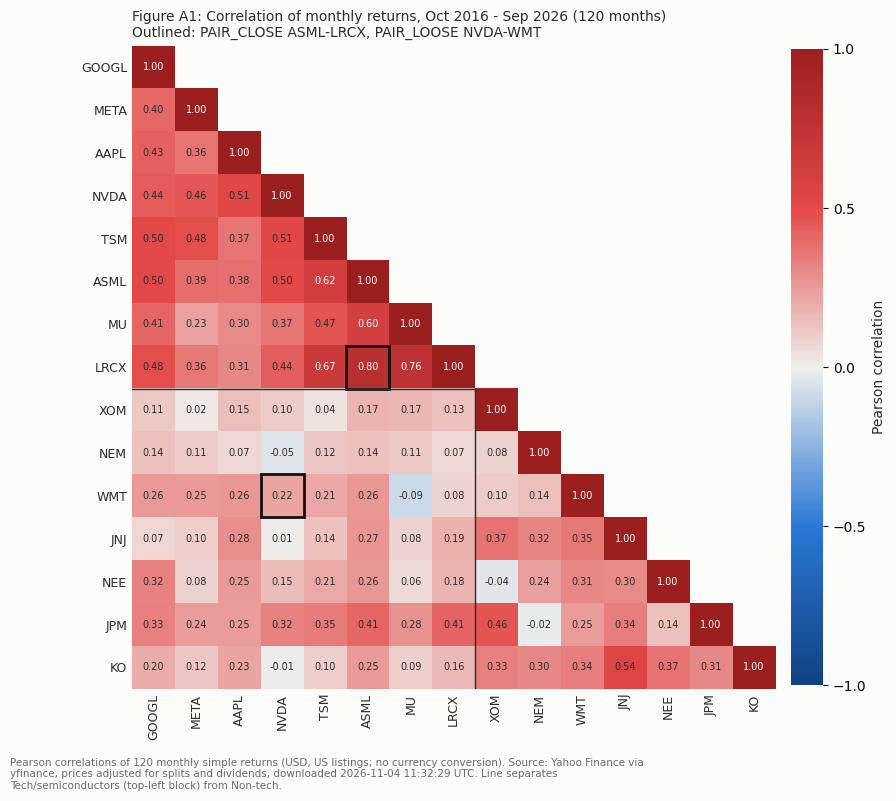

In [41]:
import textwrap
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle

# Diverging scale: blue (negative) -> neutral grey (zero) -> red (positive)
cmap = LinearSegmentedColormap.from_list("blue_grey_red",
        ["#104281", "#2a78d6", "#f0efec", "#e34948", "#9c1f1f"])

n = len(TICKERS)
mask_upper = np.triu(np.ones((n, n), dtype=bool), k=1)          # hide the duplicate upper triangle
data = np.ma.masked_where(mask_upper, corr.to_numpy())

fig, ax = plt.subplots(figsize=(9, 8))
fig.patch.set_facecolor("#fcfcfb"); ax.set_facecolor("#fcfcfb")
im = ax.imshow(data, cmap=cmap, vmin=-1, vmax=1)

# Value in each visible cell (dark text on pale cells, white text on strong ones)
for i in range(n):
    for j in range(i + 1):
        v = corr.iat[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(v) > 0.55 else "#2b2b29")

# Outline the two pairs (in the lower triangle: row = later stock, column = earlier stock)
for pair in (PAIR_CLOSE, PAIR_LOOSE):
    r, c = sorted((TICKERS.index(pair[0]), TICKERS.index(pair[1])), reverse=True)
    ax.add_patch(Rectangle((c - 0.5, r - 0.5), 1, 1, fill=False, edgecolor="#111111", linewidth=2))

# Separate the two blocks: Tech/semiconductors (first 8) vs Non-tech (last 7)
k = len(TICKERS_TECH) - 0.5
ax.plot([-0.5, k], [k, k], color="#2b2b29", linewidth=1)
ax.plot([k, k], [k, n - 0.5], color="#2b2b29", linewidth=1)

ax.set_xticks(range(n)); ax.set_xticklabels(TICKERS, rotation=90, fontsize=9, color="#2b2b29")
ax.set_yticks(range(n)); ax.set_yticklabels(TICKERS, fontsize=9, color="#2b2b29")
for s in ax.spines.values():
    s.set_visible(False)
ax.tick_params(length=0)

cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02, ticks=[-1, -0.5, 0, 0.5, 1])
cb.set_label("Pearson correlation", color="#2b2b29"); cb.outline.set_visible(False)
ax.set_title("Figure A1: Correlation of monthly returns, Oct 2016 - Sep 2026 (120 months)\n"
             f"Outlined: PAIR_CLOSE {PAIR_CLOSE[0]}-{PAIR_CLOSE[1]}, PAIR_LOOSE {PAIR_LOOSE[0]}-{PAIR_LOOSE[1]}",
             fontsize=10, color="#2b2b29", loc="left")
fig.text(0.01, 0.005, textwrap.fill(
    f"Pearson correlations of {N_RETURNS_EXPECTED} monthly simple returns (USD, US listings; no currency conversion). "
    f"Source: Yahoo Finance via yfinance, prices adjusted for splits and dividends, downloaded {DOWNLOAD_UTC}. "
    "Line separates Tech/semiconductors (top-left block) from Non-tech.", 120), fontsize=7.5, color="#6b6a66",
    ha="left", va="bottom")
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig(FIGURES_DIR / "correlation_heatmap.png", dpi=300, facecolor=fig.get_facecolor())
print("Saved outputs/figures/correlation_heatmap.png (300 dpi)")
plt.show()

**What to check in the output**
- **Saved outputs/figures/correlation_heatmap.png (300 dpi)**. Open the PNG to check it's sharp and the labels are readable.
- The **top-left block** (Tech/semis with Tech/semis) should be the reddest, especially the chip-equipment and semiconductor cluster ASML / LRCX / TSM / NVDA / MU.
- The **bottom-left block** (Non-tech rows against Tech columns) should be paler.
- The two outlined cells are your pairs: ASML–LRCX should be strongly red and NVDA–WMT pale.
- This figure is **optional support material**. Only include it if it helps your argument.

## Step 14: Annualised covariance matrix and mean vector (the Markowitz inputs)

**What this does.** Builds the two inputs every frontier calculation uses, from the same 120 monthly returns:

**Annualised mean vector** (equation (3), stacked for all 15 stocks)
$$\boldsymbol{\mu} = 12\,\bar{\mathbf{R}} = \begin{pmatrix}\mu_1 \\ \vdots \\ \mu_{15}\end{pmatrix} \tag{7}$$

**Annualised covariance matrix** (equation (5), monthly sample covariance with `ddof=1`, times 12)
$$\boldsymbol{\Sigma} = 12\,\hat{\boldsymbol{\Sigma}}_{\text{monthly}}, \qquad \Sigma_{ij} = 12\,\hat{\sigma}_{ij} \tag{8}$$

- The diagonal of $\boldsymbol{\Sigma}$ holds each stock's annualised **variance**, $\Sigma_{ii} = \sigma_i^2$. Its square root must equal the annualised SD in Table 1, and the code checks this.
- The off-diagonal entries are the covariances. Covariance = correlation × SD × SD, so this matrix combines the correlations from Step 11 with the SDs from Step 9.
- **The matrix must be positive definite**, meaning every eigenvalue is > 0. Then every portfolio has a strictly positive variance and the optimiser has a unique minimum. That is guaranteed when there are more months (120) than stocks (15) and no stock is an exact combination of the others. The code checks it.
- Saved at full precision to `outputs/tables/covariance_matrix_annual.csv` and `outputs/tables/mean_vector_annual.csv`.

In [42]:
# Equation (8): monthly SAMPLE covariance (ddof=1), annualised x 12
cov_annual = monthly_returns[TICKERS].cov(ddof=1) * PERIODS_PER_YEAR

# Equation (7): annualised mean vector, same stock order as the covariance matrix
mu_annual = monthly_returns[TICKERS].mean() * PERIODS_PER_YEAR

# numpy versions used by the portfolio functions (same order as TICKERS)
MU    = mu_annual.to_numpy()       # shape (15,)
SIGMA = cov_annual.to_numpy()      # shape (15, 15)

# ---------- Checks ----------
assert SIGMA.shape == (15, 15) and MU.shape == (15,)
assert np.allclose(SIGMA, SIGMA.T, rtol=0, atol=1e-15), "Covariance matrix must be symmetric"
# Diagonal = annualised variance -> its square root must equal Table 1's annualised SD (Step 9)
assert np.allclose(np.sqrt(np.diag(SIGMA)), stock_stats["sd_annual"].to_numpy(), rtol=0, atol=1e-14)
assert np.allclose(MU, stock_stats["mean_annual"].to_numpy(), rtol=0, atol=1e-15)
# Covariance / (SD x SD) must give back the correlation matrix from Step 11 (the 12s cancel)
sd_vec = np.sqrt(np.diag(SIGMA))
assert np.allclose(SIGMA / np.outer(sd_vec, sd_vec), corr.to_numpy(), rtol=0, atol=1e-14)
# Positive definite: all eigenvalues > 0, so every portfolio has positive variance
eigenvalues = np.linalg.eigvalsh(SIGMA)
assert eigenvalues.min() > 0, "Covariance matrix is not positive definite"
print("Checks passed: symmetric; sqrt(diagonal) = Table 1 SDs; mean vector = Table 1 means; "
      "consistent with the correlation matrix")
print(f"Positive definite: smallest eigenvalue = {eigenvalues.min():.6f}, largest = {eigenvalues.max():.6f} "
      f"(condition number {eigenvalues.max() / eigenvalues.min():.1f})")

cov_annual.to_csv(TABLES_DIR / "covariance_matrix_annual.csv")
mu_annual.rename("mean_annual").to_csv(TABLES_DIR / "mean_vector_annual.csv")
print("Saved outputs/tables/covariance_matrix_annual.csv and mean_vector_annual.csv (full precision)")

cov_annual.round(4)            # display only (decimals, e.g. 0.0267 = variance of KO; sqrt = 16.33%)

Checks passed: symmetric; sqrt(diagonal) = Table 1 SDs; mean vector = Table 1 means; consistent with the correlation matrix
Positive definite: smallest eigenvalue = 0.011735, largest = 0.707483 (condition number 60.3)
Saved outputs/tables/covariance_matrix_annual.csv and mean_vector_annual.csv (full precision)


,GOOGL,META,AAPL,NVDA,TSM,ASML,MU,LRCX,XOM,NEM,WMT,JNJ,NEE,JPM,KO
GOOGL,0.0722,0.0395,0.0312,0.0554,0.0443,0.0468,0.0614,0.0535,0.0086,0.0128,0.0132,0.0033,0.0189,0.0218,0.0088
META,0.0395,0.1326,0.0356,0.0774,0.0575,0.0493,0.0461,0.0543,0.0017,0.0133,0.0176,0.0063,0.0064,0.0216,0.0073
AAPL,0.0312,0.0356,0.0736,0.0641,0.0327,0.0356,0.0449,0.0347,0.0112,0.0067,0.0138,0.0133,0.0148,0.0162,0.0100
NVDA,0.0554,0.0774,0.0641,0.2158,0.0781,0.0815,0.0944,0.0847,0.0138,-0.0073,0.0197,0.0010,0.0155,0.0363,-0.0011
TSM,0.0443,0.0575,0.0327,0.0781,0.1081,0.0710,0.0856,0.0914,0.0034,0.0137,0.0133,0.0079,0.0149,0.0277,0.0052
ASML,0.0468,0.0493,0.0356,0.0815,0.0710,0.1207,0.1161,0.1163,0.0170,0.0164,0.0175,0.0162,0.0199,0.0350,0.0144
MU,0.0614,0.0461,0.0449,0.0944,0.0856,0.1161,0.3088,0.1761,0.0261,0.0217,-0.0096,0.0075,0.0074,0.0372,0.0086
LRCX,0.0535,0.0543,0.0347,0.0847,0.0914,0.1163,0.1761,0.1743,0.0158,0.0102,0.0063,0.0136,0.0162,0.0422,0.0111
XOM,0.0086,0.0017,0.0112,0.0138,0.0034,0.0170,0.0261,0.0158,0.0806,0.0082,0.0056,0.0180,-0.0022,0.0319,0.0154
NEM,0.0128,0.0133,0.0067,-0.0073,0.0137,0.0164,0.0217,0.0102,0.0082,0.1176,0.0094,0.0187,0.0181,-0.0019,0.0171


**What to check in the output**
- **Checks passed** and **Positive definite**, with the smallest eigenvalue greater than 0.
- **Calculator check:** the diagonal entry for KO should be about 0.0267. √0.0267 = 0.1633 = 16.33%, KO's annualised SD in Table 1. MU's diagonal should be the largest, about 0.309 (√ = 55.6%).
- These are **variances and covariances in decimals**, not percentages. They're not intuitive to read, which is why Table 1 reports SDs and Step 11 reports correlations.
- The *condition number* (largest ÷ smallest eigenvalue) shows how sensitive the optimiser will be. A value in the tens to low hundreds is normal for 15 stocks, and extremely large values would warn of near-duplicate stocks.

## Step 15: Portfolio return, risk and Sharpe-ratio functions

For a portfolio with weights $\mathbf{w} = (w_1, \dots, w_{15})^\top$ that sum to one, $\mathbf{1}^\top\mathbf{w} = \sum_i w_i = 1$:

**Expected (annualised) portfolio return**
$$\mu_p = \mathbf{w}^\top\boldsymbol{\mu} = \sum_{i=1}^{15} w_i\,\mu_i \tag{9}$$

**Portfolio variance**
$$\sigma_p^2 = \mathbf{w}^\top\boldsymbol{\Sigma}\,\mathbf{w} = \sum_{i=1}^{15}\sum_{j=1}^{15} w_i\,w_j\,\Sigma_{ij} = \underbrace{\sum_{i=1}^{15} w_i^2\,\sigma_i^2}_{\text{own variances}} + \underbrace{\sum_{i=1}^{15}\sum_{j\neq i} w_i\,w_j\,\rho_{ij}\,\sigma_i\,\sigma_j}_{\text{covariances}} \tag{10}$$

**Portfolio standard deviation**
$$\sigma_p = \sqrt{\mathbf{w}^\top\boldsymbol{\Sigma}\,\mathbf{w}} \tag{11}$$

**Sharpe ratio** (with $r_f$ = `RF_ANNUAL`, used only as the benchmark, not held as an asset)
$$S_p = \frac{\mu_p - r_f}{\sigma_p} \tag{12}$$

**Diversification inequality.** Because every $\rho_{ij} \le 1$, the covariance terms in (10) are at most what they would be if all correlations were 1. In that extreme case $\sigma_p$ would equal the weighted average of the SDs. So, for long-only weights,
$$\sigma_p \le \sum_{i=1}^{15} w_i\,\sigma_i \tag{13}$$
with equality only if every pair of stocks is perfectly correlated ($\rho_{ij} = 1$). The gap between the two sides is the **risk removed by diversification**.

**Key contrast.** The return (9) is a *straight weighted average*, so diversification costs no expected return. The SD (11) is *less* than the weighted average whenever correlations are below 1, so diversification lowers risk for free.

The code below defines one small function per equation, then tests them on the **equal-weighted portfolio** ($w_i = 1/15$ for every stock).

In [43]:
def port_return(w):
    # Equation (9): expected annual portfolio return = w' mu (weighted average of the stock means)
    return float(w @ MU)

def port_variance(w):
    # Equation (10): annual portfolio variance = w' Sigma w (includes every covariance term)
    return float(w @ SIGMA @ w)

def port_sd(w):
    # Equation (11): annual portfolio standard deviation = sqrt(w' Sigma w)
    return float(np.sqrt(port_variance(w)))

def sharpe(w):
    # Equation (12): excess return over the risk-free rate per unit of total risk
    return (port_return(w) - RF_ANNUAL) / port_sd(w)

# ---------- Test on the equal-weighted portfolio ----------
N = len(TICKERS)
w_ew = np.full(N, 1.0 / N)                       # 1/15 in every stock
assert np.isclose(w_ew.sum(), 1.0)               # budget constraint: weights sum to 1

ew_return, ew_sd, ew_sharpe = port_return(w_ew), port_sd(w_ew), sharpe(w_ew)

# The comparison for the diversification argument, equation (13)
sd_i         = np.sqrt(np.diag(SIGMA))           # individual annual SDs (= Table 1)
avg_sd       = float(w_ew @ sd_i)                # weighted (here simple) average of the 15 SDs
avg_return   = float(MU.mean())                  # simple average of the 15 means
reduction    = avg_sd - ew_sd                    # risk removed by diversification

# Split the variance, equation (10), into its two parts
own_var_part = float(np.sum(w_ew**2 * sd_i**2))  # sum of w_i^2 sigma_i^2
cov_part     = port_variance(w_ew) - own_var_part  # all the i != j covariance terms
avg_rho_off  = corr.to_numpy()[np.triu_indices(N, k=1)].mean()

# Checks: return is exactly the average (linear); SD is below the average (13)
assert np.isclose(ew_return, avg_return, rtol=0, atol=1e-15)
assert ew_sd < avg_sd

print("EQUAL-WEIGHTED PORTFOLIO (1/15 in each stock)")
print(f"  Expected return  mu_p    = {ew_return:.4%}   (average of the 15 stock means = {avg_return:.4%})")
print(f"  Standard dev.    sigma_p = {ew_sd:.4%}   (average of the 15 stock SDs   = {avg_sd:.4%})")
print(f"  Sharpe ratio     S_p     = {ew_sharpe:.4f}   (rf = {RF_ANNUAL:.2%})")
print()
print("DIVERSIFICATION")
print(f"  SD reduction: {avg_sd:.4%} - {ew_sd:.4%} = {reduction:.4%} points "
      f"({reduction / avg_sd:.1%} of the average SD removed)")
print(f"  Lowest single-stock SD (KO) = {sd_i.min():.4%} vs portfolio {ew_sd:.4%}")
print(f"  Variance split: own-variance terms {own_var_part:.6f} ({own_var_part / port_variance(w_ew):.1%}), "
      f"covariance terms {cov_part:.6f} ({cov_part / port_variance(w_ew):.1%})")
print(f"  Average pairwise correlation = {avg_rho_off:.4f} (< 1, which is why the SD falls)")

EQUAL-WEIGHTED PORTFOLIO (1/15 in each stock)
  Expected return  mu_p    = 28.1187%   (average of the 15 stock means = 28.1187%)
  Standard dev.    sigma_p = 18.0915%   (average of the 15 stock SDs   = 30.8865%)
  Sharpe ratio     S_p     = 1.3215   (rf = 4.21%)

DIVERSIFICATION
  SD reduction: 30.8865% - 18.0915% = 12.7950% points (41.4% of the average SD removed)
  Lowest single-stock SD (KO) = 16.3289% vs portfolio 18.0915%
  Variance split: own-variance terms 0.007129 (21.8%), covariance terms 0.025602 (78.2%)
  Average pairwise correlation = 0.2671 (< 1, which is why the SD falls)


**What to check in the output**
- The equal-weighted **return equals the average of the 15 means exactly**, because return is linear in the weights (eq. 9).
- The equal-weighted **SD is well below the average of the 15 SDs**: diversification, eq. (13).
- The **variance split**: with 15 stocks the own-variance terms make up only a small share. Most of the portfolio's variance comes from the **covariance** terms. This is the textbook result that, as $N$ grows, a portfolio's risk depends on the average *covariance* between stocks, not on their individual variances.
- **Hand check of the Sharpe ratio:** (μₚ − 0.0421) ÷ σₚ using the printed numbers.

## Step 16: Optimiser set-up (SLSQP), constraints and solution checks

**The two cases** (both: weights sum to 1, no risk-free asset, no other constraints, no penalties):

| Case | Bounds on every weight | Meaning |
|---|---|---|
| **No short sales** | $0 \le w_i \le 1$ | long-only; at most 100% in any one stock |
| **Bounded short sales** | $-1 \le w_i \le 1$ | short up to 100% of the portfolio in any stock, or hold up to 100% long |

**What SLSQP does (one sentence for the report).**
*SLSQP (Sequential Least-Squares Quadratic Programming) is an iterative, gradient-based optimiser: at each step it approximates the objective with a quadratic function and the constraints with linear ones, solves that simpler problem to find the next set of weights, and repeats until the weights stop improving while still satisfying the budget constraint and the bounds.*

**Implementation choices**
- **Objectives are the Step 15 functions themselves:** `port_sd` for the GMV portfolio and frontier, and `-sharpe` for the max-Sharpe portfolio.
- **Exact gradients.** Each objective is passed its *analytic* gradient (`jac`). The objective is unchanged; the gradient just tells SLSQP the exact slope, so it doesn't have to estimate it numerically, which would introduce small errors. From (11) and (12): $\nabla\sigma_p = \boldsymbol{\Sigma}\mathbf{w}/\sigma_p$ and $\nabla S_p = \big(\boldsymbol{\mu}\,\sigma_p - (\mu_p - r_f)\,\nabla\sigma_p\big)/\sigma_p^2$.
- **Tight tolerance** (`ftol = 1e-15`) and up to 1,000 iterations, consistent with the full-precision rule. At the minimum the SD is very flat, so a looser `ftol = 1e-12` pinned the SD to 10 digits but the *weights* only to about 1e-6. At 1e-15 the weights match the closed-form solution to about 1e-8. The 200 frontier points use `ftol = 1e-12`. Their SDs are still accurate to about 12 digits, which is far more than a plot needs. The top point of the bounded frontier is a single feasible portfolio (the LP corner), with no room to move around it, and SLSQP cannot handle that at 1e-15.
- **Every solve is checked** by `check_solution`: `result.success` must be True, the weights must sum to 1 within 1e-6 and lie inside the bounds within 1e-6, and for frontier points the return must hit its target within 1e-6. Any failure is recorded in `SOLVER_FAILURES` and printed.

**Maximum achievable return (for the top of the frontier).** Maximising $\mathbf{w}^\top\boldsymbol{\mu}$ subject to $\sum w_i = 1$ and the bounds is a **linear programme**, because both the objective and the constraints are linear in the weights. It is solved exactly with `scipy.optimize.linprog` (HiGHS method). No portfolio under the bounds can have a higher expected return.

In [44]:
from scipy.optimize import linprog

# ---------- The two cases ----------
CASES = {
    "no short":      BOUNDS_NO_SHORT,        # (0, 1)  for every weight
    "bounded short": BOUNDS_BOUNDED_SHORT,   # (-1, 1) for every weight
}
TOL = 1e-6                                   # tolerance for the weight / target checks
SLSQP_OPTIONS          = {"ftol": 1e-15, "maxiter": 1000}  # GMV / max-Sharpe: weights accurate to ~1e-8
SLSQP_OPTIONS_FRONTIER = {"ftol": 1e-12, "maxiter": 1000}  # frontier points: SD accurate to ~1e-12 (enough to plot);
                                                            # 1e-15 fails at the single-point top of the bounded frontier

# ---------- Exact gradients of the Step 15 objectives (speed + precision; objectives unchanged) ----------
def grad_port_sd(w):
    # d sigma_p / d w = Sigma w / sigma_p
    return SIGMA @ w / port_sd(w)

def neg_sharpe(w):
    # minimising -Sharpe is the same as maximising Sharpe
    return -sharpe(w)

def grad_neg_sharpe(w):
    # d(-S)/dw = -( mu * sigma_p - (mu_p - rf) * dsigma_p/dw ) / sigma_p^2
    s = port_sd(w)
    return -(MU * s - (port_return(w) - RF_ANNUAL) * grad_port_sd(w)) / s**2

# ---------- Constraints: budget (always) and target return (frontier only) ----------
BUDGET = {"type": "eq", "fun": lambda w: np.sum(w) - 1.0, "jac": lambda w: np.ones_like(w)}   # sum(w) = 1

def target_return_constraint(target):
    # port_return(w) = target  (an equality constraint for one frontier point)
    return {"type": "eq", "fun": lambda w: port_return(w) - target, "jac": lambda w: MU}

def solve(objective, gradient, bounds, x0, extra_constraints=(), options=None):
    # One SLSQP run: same bounds on every weight, budget constraint plus any extra constraints
    return minimize(objective, x0, jac=gradient, method="SLSQP",
                    bounds=[bounds] * len(TICKERS),
                    constraints=[BUDGET, *extra_constraints],
                    options=options or SLSQP_OPTIONS)

# ---------- Check every solution; record any failure ----------
SOLVER_FAILURES = []

def check_solution(res, bounds, label, target=None):
    # Returns True if the solve succeeded AND the weights satisfy every constraint (within TOL)
    w, lo, hi = res.x, bounds[0], bounds[1]
    problems = []
    if not res.success:                         problems.append(f"success=False ({res.message})")
    if abs(w.sum() - 1) > TOL:                  problems.append(f"sum(w) = {w.sum():.10f}")
    if (w < lo - TOL).any() or (w > hi + TOL).any():
        problems.append(f"bounds broken: min {w.min():.8f}, max {w.max():.8f}")
    if target is not None and abs(port_return(w) - target) > TOL:
        problems.append(f"return {port_return(w):.8f} vs target {target:.8f}")
    if problems:
        SOLVER_FAILURES.append((label, problems))
        print(f"FAILED  {label}: " + "; ".join(problems))
    return not problems

# ---------- Maximum achievable return in each case: a linear programme ----------
MAX_RETURN = {}
for case, bounds in CASES.items():
    lp = linprog(c=-MU,                                  # maximise mu'w  <=>  minimise -mu'w
                 A_eq=np.ones((1, len(TICKERS))), b_eq=[1.0],
                 bounds=[bounds] * len(TICKERS), method="highs")
    assert lp.success, f"linprog failed for {case}: {lp.message}"
    MAX_RETURN[case] = {"return": -lp.fun, "weights": lp.x}
    held = pd.Series(lp.x, index=TICKERS).round(6)
    print(f"Max achievable return ({case}): {-lp.fun:.4%}")
    print(f"   long : {', '.join(held[held > 0].index)}")
    if (held < 0).any():
        print(f"   short: {', '.join(held[held < 0].index)}")

Max achievable return (no short): 60.5830%
   long : NVDA
Max achievable return (bounded short): 198.9119%
   long : GOOGL, META, AAPL, NVDA, TSM, ASML, MU, LRCX
   short: XOM, NEM, WMT, JNJ, NEE, JPM, KO


**What to check in the output**
- **No short sales:** the maximum return is 100% in the single highest-mean stock, **NVDA (60.58%)**. With weights in [0, 1], putting everything into the best stock always gives the highest return.
- **Bounded short sales:** the LP goes **+100% long in the 8 highest-mean stocks and −100% short in the 7 lowest** (8 − 7 = 1, so the weights still sum to 1). This leveraged long-short position has a very high expected return and very high risk. The top of the bounded frontier is therefore an extreme portfolio that no one would actually hold, but it is where the brief's constraints allow the frontier to reach.
- No `FAILED` lines.

## Step 17: Global minimum-variance (GMV) portfolios

**What this does.** For each case, minimises `port_sd(w)` (equation 11) subject to $\sum w_i = 1$ and the bounds. The starting point is the equal-weighted portfolio. Minimising variance has a single global minimum because $\boldsymbol{\Sigma}$ is positive definite (Step 14), so one start is enough.

**Independent cross-check (bounded case).** Without bounds, the GMV portfolio has a closed-form solution:
$$\mathbf{w}_{\text{GMV}} = \frac{\boldsymbol{\Sigma}^{-1}\mathbf{1}}{\mathbf{1}^\top\boldsymbol{\Sigma}^{-1}\mathbf{1}} \tag{14}$$
If none of its weights is beyond ±1, the [−1, 1] bounds don't bind and SLSQP must reproduce (14). The code checks this. In the no-short case some weights hit 0, so (14) does not apply and there is no closed form.

In [45]:
PORTFOLIOS = {}                                  # label -> weights; filled in Steps 17-18
w_start = np.full(len(TICKERS), 1.0 / len(TICKERS))

for case, bounds in CASES.items():
    label = f"GMV ({case})"
    res = solve(port_sd, grad_port_sd, bounds, w_start)
    check_solution(res, bounds, label)
    PORTFOLIOS[label] = res.x
    print(f"{label:<22} return {port_return(res.x):.4%}   SD {port_sd(res.x):.4%}   "
          f"Sharpe {sharpe(res.x):.4f}   iterations {res.nit}")

# ---------- Cross-check with the closed-form GMV, equation (14) ----------
ones = np.ones(len(TICKERS))
w_gmv_formula = np.linalg.solve(SIGMA, ones)            # Sigma^-1 1   (solve is more accurate than inverting)
w_gmv_formula /= ones @ w_gmv_formula                    # divide by 1' Sigma^-1 1
lo, hi = BOUNDS_BOUNDED_SHORT
if (w_gmv_formula >= lo).all() and (w_gmv_formula <= hi).all():
    gap = np.abs(PORTFOLIOS["GMV (bounded short)"] - w_gmv_formula).max()
    assert gap < TOL, f"SLSQP and formula (14) disagree by {gap}"
    print(f"\nCross-check: formula (14) weights lie in [{lo}, {hi}], so bounds don't bind; "
          f"max weight gap SLSQP vs formula = {gap:.2e}")
    print(f"             SD: SLSQP {port_sd(PORTFOLIOS['GMV (bounded short)']):.10%}  vs  formula {port_sd(w_gmv_formula):.10%}")

# Weights in % for display (rounded for display only)
(pd.DataFrame({k: v for k, v in PORTFOLIOS.items()}, index=TICKERS) * 100).round(2)

GMV (no short)         return 16.2208%   SD 12.6350%   Sharpe 0.9506   iterations 28
GMV (bounded short)    return 16.1193%   SD 12.3430%   Sharpe 0.9649   iterations 30

Cross-check: formula (14) weights lie in [-1.0, 1.0], so bounds don't bind; max weight gap SLSQP vs formula = 8.19e-09
             SD: SLSQP 12.3429597324%  vs  formula 12.3429597324%


,GMV (no short),GMV (bounded short)
GOOGL,5.00,5.96
META,2.61,2.97
AAPL,1.98,1.03
NVDA,0.00,1.23
TSM,2.01,5.54
ASML,0.00,-11.35
MU,0.95,4.19
LRCX,0.00,-1.35
XOM,7.02,6.34
NEM,1.72,1.29


**What to check in the output**
- No `FAILED` lines, and both weight columns sum to 100%.
- **No short:** the GMV portfolio has a **lower SD than any single stock** (KO is the lowest at 16.33%) and lower than the equal-weighted portfolio (18.09%). It should be dominated by the low-risk, low-correlation stocks (KO, JNJ, WMT, NEE), and the riskiest stocks should get **0%**: those are binding bounds.
- **Bounded short:** its SD is **at or below** the no-short GMV. Relaxing a constraint can never make the minimum worse. A few weights are **negative** (short positions).
- **Cross-check:** the maximum weight gap against formula (14) should be about 1e-8, far inside the 1e-6 tolerance, and the two SDs should agree to every printed digit.

## Step 18: Maximum-Sharpe portfolios (multi-start)

**What this does.** For each case, minimises $-S_p$ (equation 12) subject to $\sum w_i = 1$ and the bounds. This gives the portfolio with the highest excess return per unit of risk, using `RF_ANNUAL` = 4.21% as the benchmark only (there is no risk-free asset in the portfolio).

**Multi-start.** The Sharpe ratio is a *ratio*, so in principle SLSQP could stop at a local optimum that depends on where it starts. To guard against this, each case is solved from:
- the **equal-weighted** portfolio, and
- **20 random feasible** starting portfolios (random weights inside the bounds that sum to 1), using a fixed random seed (`2026`) so the results can be reproduced.

The best solution that passes every check is kept. The spread of the Sharpe ratios across the 21 starts is printed: if they all agree, there is no local-optimum problem.

**Cross-check (bounded case).** Without bounds, the max-Sharpe (tangency) portfolio has a closed form:
$$\mathbf{w}_{\text{MS}} = \frac{\boldsymbol{\Sigma}^{-1}(\boldsymbol{\mu} - r_f\mathbf{1})}{\mathbf{1}^\top\boldsymbol{\Sigma}^{-1}(\boldsymbol{\mu} - r_f\mathbf{1})} \tag{15}$$
If its weights lie within ±1, SLSQP must reproduce it.

In [46]:
rng = np.random.default_rng(2026)            # fixed seed -> reproducible random starts
N_RANDOM_STARTS = 20

def random_feasible_start(bounds):
    # Random weights inside the bounds that sum to 1
    lo, hi = bounds
    while True:
        if lo == 0:
            w = rng.dirichlet(np.ones(len(TICKERS)))           # random long-only weights summing to 1
        else:
            w = rng.uniform(lo, hi, len(TICKERS))
            w += (1 - w.sum()) / len(TICKERS)                   # shift so the weights sum to 1
        if (w >= lo).all() and (w <= hi).all():
            return w

multistart_log = []
for case, bounds in CASES.items():
    label = f"Max Sharpe ({case})"
    starts = [w_start] + [random_feasible_start(bounds) for _ in range(N_RANDOM_STARTS)]
    best = None
    for k, x0 in enumerate(starts):
        res = solve(neg_sharpe, grad_neg_sharpe, bounds, x0)
        ok = check_solution(res, bounds, f"{label} start {k}")
        multistart_log.append({"portfolio": label, "start": "equal weights" if k == 0 else f"random {k}",
                               "success": ok, "sharpe": sharpe(res.x)})
        if ok and (best is None or sharpe(res.x) > sharpe(best.x)):
            best = res
    assert best is not None, f"No valid solution for {label}"
    PORTFOLIOS[label] = best.x
    s = pd.DataFrame(multistart_log).query("portfolio == @label and success")["sharpe"]
    print(f"{label:<27} return {port_return(best.x):.4%}   SD {port_sd(best.x):.4%}   Sharpe {sharpe(best.x):.6f}")
    print(f"{'':<27} {len(s)}/{len(starts)} starts valid; Sharpe range across starts "
          f"{s.min():.10f} to {s.max():.10f} (spread {s.max() - s.min():.1e})")

# ---------- Cross-check with the closed-form tangency portfolio, equation (15) ----------
w_ms_formula = np.linalg.solve(SIGMA, MU - RF_ANNUAL)
w_ms_formula /= w_ms_formula.sum()
lo, hi = BOUNDS_BOUNDED_SHORT
if (w_ms_formula >= lo).all() and (w_ms_formula <= hi).all():
    gap = np.abs(PORTFOLIOS["Max Sharpe (bounded short)"] - w_ms_formula).max()
    assert gap < TOL, f"SLSQP and formula (15) disagree by {gap}"
    print(f"\nCross-check: formula (15) weights lie in [{lo}, {hi}]; max weight gap SLSQP vs formula = {gap:.2e}")
    print(f"             Sharpe: SLSQP {sharpe(PORTFOLIOS['Max Sharpe (bounded short)']):.10f}  vs  formula {sharpe(w_ms_formula):.10f}")

(pd.DataFrame({k: PORTFOLIOS[k] for k in ["Max Sharpe (no short)", "Max Sharpe (bounded short)"]},
              index=TICKERS) * 100).round(2)            # weights in %, display only

Max Sharpe (no short)       return 33.3952%   SD 19.5300%   Sharpe 1.494376
                            21/21 starts valid; Sharpe range across starts 1.4943756167 to 1.4943756167 (spread 6.7e-16)
Max Sharpe (bounded short)  return 35.0447%   SD 19.8608%   Sharpe 1.552540
                            21/21 starts valid; Sharpe range across starts 1.5525400296 to 1.5525400296 (spread 6.7e-16)

Cross-check: formula (15) weights lie in [-1.0, 1.0]; max weight gap SLSQP vs formula = 4.64e-09
             Sharpe: SLSQP 1.5525400296  vs  formula 1.5525400296


,Max Sharpe (no short),Max Sharpe (bounded short)
GOOGL,0.00,-4.39
META,0.00,-10.21
AAPL,8.08,11.08
NVDA,22.07,26.55
TSM,0.00,3.63
ASML,0.00,-22.38
MU,9.94,9.51
LRCX,5.09,18.90
XOM,0.75,-0.29
NEM,11.73,13.84


**What to check in the output**
- **21/21 starts valid** in each case, and a **tiny Sharpe spread** across starts (about 1e-12 or smaller). Every start reaches the same optimum, so it is the global maximum, not a local one.
- **Bounded short Sharpe ≥ no-short Sharpe.** Allowing shorts can only help.
- **Cross-check:** the weight gap against formula (15) should be about 1e-8 or smaller, and the two Sharpe ratios should agree to every printed digit.
- **No short:** many weights are exactly 0%. The optimiser drops stocks whose return per unit of risk isn't worth their contribution to portfolio risk. Expect large weights in NVDA (best return per unit of risk) and in low-correlation diversifiers such as WMT and NEM.

## Step 19: The two efficient frontiers

**What this does.** For each case:
1. Takes 100 evenly spaced **target returns** from the GMV return (Step 17) up to the maximum achievable return (Step 16).
2. For each target, minimises `port_sd(w)` subject to $\sum w_i = 1$, $\mathbf{w}^\top\boldsymbol{\mu} = \text{target}$ (equation 9) and the bounds.

Each point is the **lowest-risk portfolio for that level of expected return**. Together the points trace the efficient frontier, the upper part of the minimum-variance frontier, starting at the GMV portfolio.

- **Warm start:** each solve starts from the previous point's weights. Neighbouring frontier portfolios are similar, so this is fast and stable.
- Every point is checked with `check_solution`, including whether the target return was hit within 1e-6.
- The frontiers are saved with their weights at full precision to `outputs/tables/frontier_no_short.csv` and `frontier_bounded_short.csv`.

In [47]:
N_FRONTIER = 100
FRONTIERS = {}

for case, bounds in CASES.items():
    targets = np.linspace(port_return(PORTFOLIOS[f"GMV ({case})"]), MAX_RETURN[case]["return"], N_FRONTIER)
    x0 = PORTFOLIOS[f"GMV ({case})"]                      # first point starts from the GMV weights
    rows, n_fail = [], 0
    for k, target in enumerate(targets):
        res = solve(port_sd, grad_port_sd, bounds, x0, extra_constraints=[target_return_constraint(target)],
                    options=SLSQP_OPTIONS_FRONTIER)
        ok = check_solution(res, bounds, f"Frontier ({case}) point {k + 1}", target=target)
        n_fail += not ok
        rows.append({"target_return": target, "return": port_return(res.x), "sd": port_sd(res.x),
                     "sharpe": sharpe(res.x), "ok": ok, **dict(zip(TICKERS, res.x))})
        x0 = res.x                                        # warm start for the next target
    FRONTIERS[case] = pd.DataFrame(rows)
    FRONTIERS[case].to_csv(TABLES_DIR / f"frontier_{case.replace(' ', '_')}.csv", index=False)
    f = FRONTIERS[case]
    print(f"Frontier ({case}): {len(f)} points, {n_fail} failed | return {f['return'].min():.2%} -> {f['return'].max():.2%} "
          f"| SD {f['sd'].min():.2%} -> {f['sd'].max():.2%} | best Sharpe on grid {f['sharpe'].max():.4f}")

# Sanity checks on the shape of each frontier
for case, f in FRONTIERS.items():
    assert np.all(np.diff(f["sd"]) > -1e-9), f"SD should rise along the efficient frontier ({case})"
    assert f["sharpe"].max() <= sharpe(PORTFOLIOS[f"Max Sharpe ({case})"]) + 1e-9, \
        f"No frontier point may beat the max-Sharpe portfolio ({case})"
# Bounded frontier must be at least as good: at the same return, never higher SD (compare where both exist)
fb, fn = FRONTIERS["bounded short"], FRONTIERS["no short"]
sd_bounded_at_ns_returns = np.interp(fn["return"], fb["return"], fb["sd"])
assert (sd_bounded_at_ns_returns <= fn["sd"] + 1e-6).all(), "Bounded frontier should lie on or left of no-short frontier"
print("\nShape checks passed: SD rises along each frontier; no point beats its max-Sharpe portfolio; "
      "bounded-short frontier lies on or to the left of the no-short frontier")
print(f"Total solver failures so far: {len(SOLVER_FAILURES)}")

Frontier (no short): 100 points, 0 failed | return 16.22% -> 60.58% | SD 12.64% -> 46.46% | best Sharpe on grid 1.4944
Frontier (bounded short): 100 points, 0 failed | return 16.12% -> 198.91% | SD 12.34% -> 207.76% | best Sharpe on grid 1.5524

Shape checks passed: SD rises along each frontier; no point beats its max-Sharpe portfolio; bounded-short frontier lies on or to the left of the no-short frontier
Total solver failures so far: 0


**What to check in the output**
- **100 points, 0 failed** for each frontier, and **Total solver failures so far: 0**.
- **No short:** returns run from the GMV return up to **60.58% (100% NVDA)**, where the SD equals NVDA's own 46.46%.
- **Bounded short:** returns run much higher, up to the LP maximum (the leveraged long-short portfolio), with a very high SD at the top.
- **Shape checks passed:**
  - Moving up a frontier, risk only rises.
  - No frontier point has a higher Sharpe ratio than the max-Sharpe portfolio found in Step 18.
  - The bounded frontier is never to the right of the no-short frontier. Wider bounds can only lower the minimum risk for a given return.

## Step 20: Summary of the four portfolios

**What this does.** Collects the four portfolios under consistent labels and prints their annualised return, SD, Sharpe ratio and weights:

| Label | Case | Objective |
|---|---|---|
| `GMV (no short)` | $0 \le w_i \le 1$ | minimum SD |
| `Max Sharpe (no short)` | $0 \le w_i \le 1$ | maximum Sharpe ratio |
| `GMV (bounded short)` | $-1 \le w_i \le 1$ | minimum SD |
| `Max Sharpe (bounded short)` | $-1 \le w_i \le 1$ | maximum Sharpe ratio |

The table is saved at full precision to `outputs/tables/optimal_portfolios.csv` (weights as decimals). The display below is in % and rounded for display only.

In [48]:
PORTFOLIO_LABELS = ["GMV (no short)", "Max Sharpe (no short)", "GMV (bounded short)", "Max Sharpe (bounded short)"]
assert set(PORTFOLIOS) == set(PORTFOLIO_LABELS)

summary = pd.DataFrame({
    label: {"Expected return": port_return(PORTFOLIOS[label]),
            "SD":              port_sd(PORTFOLIOS[label]),
            "Sharpe":          sharpe(PORTFOLIOS[label]),
            "Sum of weights":  PORTFOLIOS[label].sum(),
            "No. of stocks held (|w| > 0.01%)": int((np.abs(PORTFOLIOS[label]) > 1e-4).sum()),
            "Total short (sum of negative w)":  PORTFOLIOS[label][PORTFOLIOS[label] < 0].sum(),
            **dict(zip(TICKERS, PORTFOLIOS[label]))}
    for label in PORTFOLIO_LABELS
})
summary.to_csv(TABLES_DIR / "optimal_portfolios.csv")          # full precision

# Final check of all four portfolios against the constraints
for label in PORTFOLIO_LABELS:
    lo, hi = CASES["no short" if "no short" in label else "bounded short"]
    w = PORTFOLIOS[label]
    assert abs(w.sum() - 1) <= TOL and (w >= lo - TOL).all() and (w <= hi + TOL).all(), label
print(f"All four portfolios satisfy sum(w) = 1 and their bounds (tolerance {TOL}).  "
      f"Solver failures in total: {len(SOLVER_FAILURES)}")
print("Saved outputs/tables/optimal_portfolios.csv\n")

display_tbl = summary.copy()
pct_rows = ["Expected return", "SD", "Sum of weights", "Total short (sum of negative w)", *TICKERS]
display_tbl.loc[pct_rows] = display_tbl.loc[pct_rows] * 100      # % for display
display_tbl.round(2)

All four portfolios satisfy sum(w) = 1 and their bounds (tolerance 1e-06).  Solver failures in total: 0
Saved outputs/tables/optimal_portfolios.csv



,GMV (no short),Max Sharpe (no short),GMV (bounded short),Max Sharpe (bounded short)
Expected return,16.22,33.40,16.12,35.04
SD,12.64,19.53,12.34,19.86
Sharpe,0.95,1.49,0.96,1.55
Sum of weights,100.00,100.00,100.00,100.00
No. of stocks held (|w| > 0.01%),12.00,10.00,15.00,15.00
Total short (sum of negative w),0.00,0.00,-12.70,-39.05
GOOGL,5.00,0.00,5.96,-4.39
META,2.61,0.00,2.97,-10.21
AAPL,1.98,8.08,1.03,11.08
NVDA,0.00,22.07,1.23,26.55


**What to check in the output**
- **All four portfolios satisfy sum(w) = 1 and their bounds** and **Solver failures in total: 0**.
- **Ordering checks:**
  - GMV SD (bounded) ≤ GMV SD (no short)
  - Max Sharpe (bounded) ≥ Max Sharpe (no short)
  - Each max-Sharpe portfolio has a higher return *and* a higher SD than its GMV portfolio
- **Sum of weights = 100.00%** in every column. **Total short = 0** for the no-short portfolios, and negative for the bounded-short ones.
- No weight is below −100% or above +100%.

## Step 21: Table 2 (risk and return of the four optimal portfolios)

**What this does.** Reports, for each of the four portfolios from Steps 17–18:
- the annualised mean return (%), from equation (9)
- the annualised SD (%), from equation (11)
- the Sharpe ratio, from equation (12)

A note under the table states the risk-free rate and its source, and that it is used **only** as the Sharpe-ratio benchmark (no risk-free asset is in any portfolio).

Exported to `outputs/tables/table2.csv` and `table2.xlsx`, with percentages at 2 dp and Sharpe ratios at 3 dp (**display only**; the full-precision values are in `optimal_portfolios.csv` from Step 20).

In [49]:
RF_NOTE = ("Note: Sharpe ratio = (annualised mean return - risk-free rate) / annualised SD (eq. 12). "
           f"Risk-free rate = {RF_ANNUAL:.2%} p.a.: 3-month US Treasury bill, bond-equivalent yield (BEY), "
           "source S&P Capital IQ, as of 3 Nov 2026. It is used only as the Sharpe-ratio benchmark; "
           "no risk-free asset is held in any portfolio. Percentages at 2 dp and Sharpe ratios at 3 dp for display only.")

table2 = pd.DataFrame({
    "Portfolio":                  PORTFOLIO_LABELS,
    "Short sales":                ["Not permitted [0, 1]" if "no short" in l else "Bounded [-1, 1]" for l in PORTFOLIO_LABELS],
    "Annualised mean return (%)": [port_return(PORTFOLIOS[l]) * 100 for l in PORTFOLIO_LABELS],
    "Annualised SD (%)":          [port_sd(PORTFOLIOS[l]) * 100 for l in PORTFOLIO_LABELS],
    "Sharpe ratio":               [sharpe(PORTFOLIOS[l]) for l in PORTFOLIO_LABELS],
})

# Rounded copy for presentation (display only)
table2_display = table2.round({"Annualised mean return (%)": 2, "Annualised SD (%)": 2, "Sharpe ratio": 3})

table2_display.to_csv(TABLES_DIR / "table2.csv", index=False)

# XLSX: table and number formats (title and notes added below)
with pd.ExcelWriter(TABLES_DIR / "table2.xlsx", engine="openpyxl") as xw:
    table2_display.to_excel(xw, sheet_name="Table 2", index=False)
    ws = xw.sheets["Table 2"]
    for col, fmt in (("C", "0.00"), ("D", "0.00"), ("E", "0.000")):
        for c in ws[col][1:]:
            c.number_format = fmt
    for col, width in zip("ABCDE", (30, 22, 26, 18, 13)):
        ws.column_dimensions[col].width = width

add_title_and_note("table2",
    "Table 2: Annualised mean return, SD and Sharpe ratio of the four optimal portfolios",
    [RF_NOTE, SOURCE_NOTE])
print("Saved outputs/tables/table2.csv and table2.xlsx (title + notes)\n")
print(RF_NOTE, "\n")
table2_display

Saved outputs/tables/table2.csv and table2.xlsx (title + notes)

Note: Sharpe ratio = (annualised mean return - risk-free rate) / annualised SD (eq. 12). Risk-free rate = 4.21% p.a.: 3-month US Treasury bill, bond-equivalent yield (BEY), source S&P Capital IQ, as of 3 Nov 2026. It is used only as the Sharpe-ratio benchmark; no risk-free asset is held in any portfolio. Percentages at 2 dp and Sharpe ratios at 3 dp for display only. 



,Portfolio,Short sales,Annualised mean return (%),Annualised SD (%),Sharpe ratio
0,GMV (no short),"Not permitted [0, 1]",16.22,12.64,0.951
1,Max Sharpe (no short),"Not permitted [0, 1]",33.40,19.53,1.494
2,GMV (bounded short),"Bounded [-1, 1]",16.12,12.34,0.965
3,Max Sharpe (bounded short),"Bounded [-1, 1]",35.04,19.86,1.553


**What to check in the output**
- Four rows, with the labels in this order: GMV (no short), Max Sharpe (no short), GMV (bounded short), Max Sharpe (bounded short).
- The values match Step 20: e.g. GMV (no short) 16.22% / 12.64% / 0.951.
- **Hand check of one Sharpe ratio:** (33.40 − 4.21) ÷ 19.53 = 1.494.
- The note states the rate (4.21%), the instrument (3-month T-bill, BEY), the source (S&P Capital IQ) and the date (3 Nov 2026). Open `table2.xlsx` to check the note appears under the table.

## Step 22: Table 3 (portfolio weights)

**What this does.** Shows the 15 weights (%) of each of the four portfolios, in CONFIG order (Tech/semiconductors first, then Non-tech), plus three summary rows:

| Row | Formula | Must equal |
|---|---|---|
| **Sum of weights** | $\sum_i w_i$ | 100% in every column (budget constraint) |
| **Gross exposure** | $\sum_i \lvert w_i \rvert$ | 100% if there are no shorts; above 100% when there are shorts (each short adds to the gross) |
| **No. at a bound** | count of weights at a bound | – |

**Bound flags.** A weight is "at a bound" if it is within 1e-6 of a limit **for its own case**:
- *No short* [0, 1]: a weight of **0%** (the stock is excluded) or **100%** (the whole portfolio in one stock)
- *Bounded short* [−1, 1]: a weight of **−100%** or **100%**. Here 0% is *not* a bound, because the weight could have gone negative.

Flagged cells are marked with **†** in the notebook display and in `table3.csv`, highlighted in `table3.xlsx`, and listed in a note under each table. A binding bound means the constraint is **active**: without it, the optimiser would have pushed that weight further.

Exported to `outputs/tables/table3.csv` and `table3.xlsx` at 2 dp (display only).

In [50]:
BOUND_TOL = 1e-6
W = pd.DataFrame({l: PORTFOLIOS[l] for l in PORTFOLIO_LABELS}, index=TICKERS)     # decimals, full precision

def bounds_for(label):
    return CASES["no short" if "no short" in label else "bounded short"]

# Which weights sit at a bound of their own case
at_bound = pd.DataFrame(False, index=TICKERS, columns=PORTFOLIO_LABELS)
for l in PORTFOLIO_LABELS:
    lo, hi = bounds_for(l)
    at_bound[l] = (np.abs(W[l] - lo) <= BOUND_TOL) | (np.abs(W[l] - hi) <= BOUND_TOL)

# Summary rows (full precision)
sum_row   = W.sum()                 # must be 1 (100%)
gross_row = W.abs().sum()           # sum of |w|
assert (np.abs(sum_row - 1) <= TOL).all(), "A portfolio's weights do not sum to 100%"

# Table in %, numeric, rounded for display only (+ 0.0 turns any -0.00 into 0.00)
table3 = pd.concat([
    W * 100,
    pd.DataFrame([sum_row * 100, gross_row * 100], index=["Sum of weights", "Gross exposure (sum of |w|)"]),
]).round(2) + 0.0
table3 = table3.astype(object)                                   # lets the count row hold whole numbers
table3.loc["No. of weights at a bound"] = [int(n) for n in at_bound.sum()]
table3.insert(0, "Group", list(CONFIG.set_index("ticker").loc[TICKERS, "group"]) + ["", "", ""])
table3.index.name = "Ticker"

# Text version for display and CSV: 2 dp everywhere, a dagger on every weight at a bound
shown = table3.copy()
for l in PORTFOLIO_LABELS:
    for t in table3.index[:-1]:                                   # weights + sum + gross rows
        shown.at[t, l] = f"{table3.at[t, l]:.2f}" + (" †" if t in TICKERS and at_bound.at[t, l] else "")

flag_list = [f"{t} in {l} = {W.at[t, l]:.2%}" for l in PORTFOLIO_LABELS for t in TICKERS if at_bound.at[t, l]]
FLAG_NOTE = ("Note: weights in % of portfolio value; each column sums to 100%. Gross exposure = sum of |w|. "
             "Weights at a bound of their own case (no short: 0% or 100%; bounded short: -100% or 100%) "
             f"are highlighted (marked † in the CSV): {'; '.join(flag_list) if flag_list else 'none'}.")

# CSV: text version (2 dp, dagger = at a bound); title and notes added below
with open(TABLES_DIR / "table3.csv", "w", newline="", encoding="utf-8-sig") as f:   # utf-8-sig: Excel shows the dagger correctly
    shown.to_csv(f)

# XLSX: number format, highlight at-bound cells, bold summary rows, note underneath
from openpyxl.styles import PatternFill, Font
with pd.ExcelWriter(TABLES_DIR / "table3.xlsx", engine="openpyxl") as xw:
    table3.to_excel(xw, sheet_name="Table 3")
    ws = xw.sheets["Table 3"]
    highlight = PatternFill(start_color="FFE9C7", end_color="FFE9C7", fill_type="solid")
    for r, t in enumerate(TICKERS, start=2):                      # row 1 = header
        for c, l in enumerate(PORTFOLIO_LABELS, start=3):         # col A = Ticker, B = Group
            cell = ws.cell(row=r, column=c)
            cell.number_format = "0.00"
            if at_bound.at[t, l]:
                cell.fill = highlight
    for r in range(len(TICKERS) + 2, len(TICKERS) + 5):           # the three summary rows
        for c in range(1, 7):
            ws.cell(row=r, column=c).font = Font(bold=True)
            if c >= 3 and r < len(TICKERS) + 4:
                ws.cell(row=r, column=c).number_format = "0.00"
    for col, width in zip("ABCDEF", (28, 20, 16, 22, 21, 27)):
        ws.column_dimensions[col].width = width

add_title_and_note("table3", "Table 3: Weights of the four optimal portfolios (% of portfolio value)",
                   [FLAG_NOTE, SOURCE_NOTE])
print("Saved outputs/tables/table3.csv and table3.xlsx (title + notes)")
print(f"Sum of weights: {', '.join(f'{v:.10%}' for v in sum_row)}")
print(f"Weights at a bound ({len(flag_list)}):")
for s in flag_list:
    print("   ", s)

shown                                                             # notebook display (2 dp, dagger = at a bound)

Saved outputs/tables/table3.csv and table3.xlsx (title + notes)
Sum of weights: 100.0000000000%, 100.0000000000%, 100.0000000000%, 100.0000000000%
Weights at a bound (8):
    NVDA in GMV (no short) = 0.00%
    ASML in GMV (no short) = 0.00%
    LRCX in GMV (no short) = 0.00%
    GOOGL in Max Sharpe (no short) = 0.00%
    META in Max Sharpe (no short) = 0.00%
    TSM in Max Sharpe (no short) = 0.00%
    ASML in Max Sharpe (no short) = 0.00%
    NEE in Max Sharpe (no short) = 0.00%


,Group,GMV (no short),Max Sharpe (no short),GMV (bounded short),Max Sharpe (bounded short)
Ticker,,,,,
GOOGL,Tech/semiconductors,5.00,0.00 †,5.96,-4.39
META,Tech/semiconductors,2.61,0.00 †,2.97,-10.21
AAPL,Tech/semiconductors,1.98,8.08,1.03,11.08
NVDA,Tech/semiconductors,0.00 †,22.07,1.23,26.55
TSM,Tech/semiconductors,2.01,0.00 †,5.54,3.63
ASML,Tech/semiconductors,0.00 †,0.00 †,-11.35,-22.38
MU,Tech/semiconductors,0.95,9.94,4.19,9.51
LRCX,Tech/semiconductors,0.00 †,5.09,-1.35,18.90
XOM,Non-tech,7.02,0.75,6.34,-0.29


**What to check in the output**
- **Sum of weights = 100%** in every column, to 10 decimal places (the assert would have stopped the cell otherwise).
- **Gross exposure:** exactly 100% for the two no-short portfolios, and above 100% for the bounded-short ones. Gross − 100% = 2 × total short. For example, if the total short is −39.05%, the gross is 100 + 2 × 39.05 = 178.10%.
- **Bound flags:** in the no-short portfolios, the † cells are stocks excluded at **0%**. In the bounded-short portfolios **no weight reaches ±100%**, which is why the closed-form formulas (14) and (15) matched SLSQP in Steps 17–18.
- Open `table3.xlsx`: the flagged cells are shaded, the summary rows are bold, and the note sits underneath.

## Step 23: Automatic sanity checks, and why short sales change the frontier

**The key idea: the feasible sets are nested.** Every no-short portfolio is also allowed under bounded short sales:
$$\mathcal{F}_{\text{no short}} = \{\mathbf{w} : \textstyle\sum_i w_i = 1,\ 0 \le w_i \le 1\} \;\subset\; \mathcal{F}_{\text{bounded}} = \{\mathbf{w} : \textstyle\sum_i w_i = 1,\ -1 \le w_i \le 1\}$$
Allowing short sales only **adds** choices and never removes any. Optimising over a larger set can never give a worse answer. Checks 1, 2 and 5 rest on this, and checks 3 and 4 follow from the definitions of the two special portfolios.

| # | Check | Why it must hold in theory |
|---|---|---|
| 1 | Sharpe(Max Sharpe, bounded) ≥ Sharpe(Max Sharpe, no short) | The no-short max-Sharpe portfolio is also feasible with bounded shorts, so the bounded maximum is at least as high. It is **strictly** higher only if the no-short constraint binds, i.e. the unconstrained optimum would want some $w_i < 0$. |
| 2 | SD(GMV, bounded) ≤ SD(GMV, no short) | Same reasoning for a minimum: a larger feasible set can only lower, or leave unchanged, the smallest achievable variance. Shorting lets the optimiser **hedge**: going short one stock offsets the risk of a highly correlated long position. |
| 3 | Sharpe(Max Sharpe) ≥ Sharpe of every point on its own frontier | The max-Sharpe portfolio maximises (12) over *all* feasible portfolios, and every frontier point is a feasible portfolio. Geometrically, the line from $r_f$ through the max-Sharpe portfolio is the steepest line that touches the frontier (tangency). Every other frontier point lies on a flatter line. |
| 4 | Each GMV portfolio is the leftmost point of its frontier | The GMV portfolio minimises SD over *all* feasible portfolios, so no frontier point can have a lower SD. The efficient frontier begins at the GMV portfolio and runs upward from it. |
| 5 *(extra)* | Bounded frontier lies on or to the left of the no-short frontier | For any target return the no-short frontier reaches, the no-short frontier portfolio is also feasible with bounded shorts. So the bounded frontier's minimum SD at that return is no higher: the whole frontier shifts **left (less risk) and up (more return)**. |

**What the shift looks like in practice**
- **Shift left and up (checks 1, 2 and 5).** Short positions can hedge correlated risks. Here the clearest case is shorting ASML against long LRCX, a 0.80-correlated pair.
- **The bounded frontier extends much higher.** Without shorts, a portfolio's return is a weighted average of the stock returns with non-negative weights, so it can never exceed the best single stock (NVDA, 60.58%). With shorts, the proceeds of short positions fund extra long positions (leverage), so returns, and risk, can go far above any single stock. The limit is the ±100% bound on each weight (Step 16 LP: 198.91%).
- **The gap is largest where the no-short bounds bind most.** If no weight were at 0% in the no-short solutions, the two cases would give the *same* GMV and max-Sharpe portfolios. Table 3 shows which bounds bind.

Each check prints PASS or FAIL with the numbers behind it. Comparisons with frontier points allow a 1e-9 tolerance, because frontier points are solved at `ftol = 1e-12`.

In [51]:
CHECK_TOL = 1e-9
check_results = []

def report(no, name, passed, detail):
    check_results.append({"check": no, "description": name, "result": "PASS" if passed else "FAIL", "detail": detail})
    print(f"[{'PASS' if passed else 'FAIL'}] {no}. {name}\n        {detail}")

# 1. Allowing shorts cannot lower the maximum Sharpe ratio
s_b, s_n = sharpe(PORTFOLIOS["Max Sharpe (bounded short)"]), sharpe(PORTFOLIOS["Max Sharpe (no short)"])
report(1, "Sharpe(Max Sharpe bounded short) >= Sharpe(Max Sharpe no short)", s_b >= s_n - CHECK_TOL,
       f"{s_b:.6f} vs {s_n:.6f}  (gain from shorting {s_b - s_n:+.6f})")

# 2. Allowing shorts cannot raise the minimum variance
v_b, v_n = port_sd(PORTFOLIOS["GMV (bounded short)"]), port_sd(PORTFOLIOS["GMV (no short)"])
report(2, "SD(GMV bounded short) <= SD(GMV no short)", v_b <= v_n + CHECK_TOL,
       f"{v_b:.6%} vs {v_n:.6%}  (risk reduction {v_n - v_b:.6%} points)")

# 3. Max-Sharpe portfolio beats (or ties) every point on its own frontier
for case in CASES:
    ms = sharpe(PORTFOLIOS[f"Max Sharpe ({case})"])
    best_point = FRONTIERS[case]["sharpe"].max()
    report(3, f"Max Sharpe ({case}) >= Sharpe of every point on its frontier", ms >= best_point - CHECK_TOL,
           f"max-Sharpe portfolio {ms:.6f} vs best of {len(FRONTIERS[case])} frontier points {best_point:.6f}")

# 4. GMV portfolio is the leftmost point of its frontier
for case in CASES:
    gmv_sd = port_sd(PORTFOLIOS[f"GMV ({case})"])
    min_point = FRONTIERS[case]["sd"].min()
    report(4, f"GMV ({case}) is the leftmost point of its frontier", gmv_sd <= min_point + CHECK_TOL,
           f"GMV SD {gmv_sd:.8%} vs lowest frontier SD {min_point:.8%}")

# 5 (extra). Bounded frontier on or left of the no-short frontier, compared at the no-short frontier's returns
fb, fn = FRONTIERS["bounded short"], FRONTIERS["no short"]
sd_b_interp = np.interp(fn["return"], fb["return"], fb["sd"])    # bounded SD at the same target returns
worst = (sd_b_interp - fn["sd"]).max()
report(5, "Bounded-short frontier lies on or left of the no-short frontier (extra)", worst <= 1e-6,
       f"largest (bounded SD - no-short SD) over {len(fn)} returns = {worst:.2e} "
       f"(<= 0 means never to the right; 1e-6 allows for interpolation between grid points)")

n_fail = sum(r["result"] == "FAIL" for r in check_results)
pd.DataFrame(check_results).to_csv(TABLES_DIR / "sanity_checks.csv", index=False)
print(f"\n{len(check_results) - n_fail} of {len(check_results)} checks PASS.  Saved outputs/tables/sanity_checks.csv")
assert n_fail == 0, "At least one sanity check FAILED - investigate before using the results"

[PASS] 1. Sharpe(Max Sharpe bounded short) >= Sharpe(Max Sharpe no short)
        1.552540 vs 1.494376  (gain from shorting +0.058164)
[PASS] 2. SD(GMV bounded short) <= SD(GMV no short)
        12.342960% vs 12.635041%  (risk reduction 0.292081% points)
[PASS] 3. Max Sharpe (no short) >= Sharpe of every point on its frontier
        max-Sharpe portfolio 1.494376 vs best of 100 frontier points 1.494361
[PASS] 3. Max Sharpe (bounded short) >= Sharpe of every point on its frontier
        max-Sharpe portfolio 1.552540 vs best of 100 frontier points 1.552427
[PASS] 4. GMV (no short) is the leftmost point of its frontier
        GMV SD 12.63504119% vs lowest frontier SD 12.63504119%
[PASS] 4. GMV (bounded short) is the leftmost point of its frontier
        GMV SD 12.34295973% vs lowest frontier SD 12.34295973%
[PASS] 5. Bounded-short frontier lies on or left of the no-short frontier (extra)
        largest (bounded SD - no-short SD) over 100 returns = -2.67e-03 (<= 0 means never to the ri

**What to check in the output**
- Every line shows **[PASS]**, and the last line reads **7 of 7 checks PASS**. Checks 3 and 4 run once per case.
- **Check 1:** the gain in Sharpe ratio from shorting is positive but small (about +0.06). The no-short constraint binds (several 0% weights in Table 3), but not by much.
- **Check 2:** the risk reduction is about 0.29 percentage points. Again small, so the GMV portfolio barely needs shorts.
- **Check 3:** the best frontier point is a fraction below the max-Sharpe portfolio. That's expected: the 100-point grid doesn't land exactly on the tangency point.
- **Check 4:** the GMV SD equals the lowest frontier SD, because the first frontier point *is* the GMV return.
- **Check 5:** the largest difference is ≤ 0, apart from tiny interpolation noise.

## Step 24: Figure 1 (both efficient frontiers)

**What this does.** Plots, on one set of axes (x = annualised SD %, y = annualised mean return %):

| Element | How it is drawn |
|---|---|
| No-short frontier [0, 1] | solid **blue** line |
| Bounded-short frontier [−1, 1] | dashed **orange** line (solid vs dashed keeps the two distinct in black-and-white print) |
| The four optimal portfolios | four different markers (square, diamond, triangle, star), coloured by case and labelled with their exact Table 2 names |
| The 15 stocks | small grey points labelled with their tickers |
| Tangency lines (optional) | faint dotted lines from $r_f$ through each max-Sharpe point, labelled as an **illustration only**: no risk-free asset is in any portfolio |

**Design choices**
- **Zoom inset for the GMV portfolios.** The two GMV portfolios differ by only ~0.3 percentage points of SD (12.34% vs 12.64%), so on the main axes their markers overlap. A small magnified panel (lower right, linked by a box) shows both clearly with their names. This is itself a finding: shorting barely lowers the minimum risk.
- **Plotted window: SD 0–60%, return 0–66%.** This covers all 15 stocks and the whole no-short frontier. The bounded-short frontier keeps rising to 198.9% return at 207.8% SD. Showing all of it would squash everything else into a corner, so the caption states where it ends.
- **Readable at half a page width.** The figure is drawn 6.2 in wide. Printed at about 4.1 in (half of A4), the smallest main text (ticker labels, 10.5 pt) prints at about 7 pt. The legend sits below the plot so it hides no points.
- **Colours:** a colour-blind-safe blue/orange pair, checked with a palette validator.
- Saved as `outputs/figures/figure1_frontiers.png` (300 dpi) and `figure1_frontiers.pdf` (vector, so it stays sharp at any size; best for the report).

Saved outputs/figures/figure1_frontiers.png (300 dpi) and figure1_frontiers.pdf


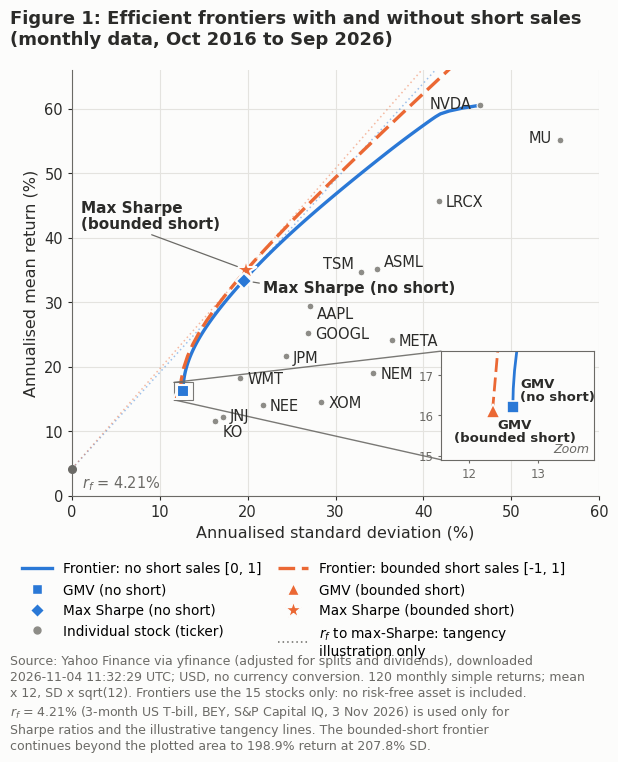

In [52]:
import textwrap
from matplotlib.lines import Line2D

# ---------- Style: sized so text stays readable when printed at half a page width ----------
# Drawn at 6.2 in wide; printed at ~4.1 in (half of A4) everything shrinks to ~66%, so the
# smallest text (ticker labels, 10.5 pt) prints at ~7 pt.
INK, MUTED, GRID, SURFACE = "#2b2b29", "#6b6a66", "#e4e3df", "#fcfcfb"
COL = {"no short": "#2a78d6", "bounded short": "#eb6834"}          # colour-blind-safe pair (validated)
LINESTYLE = {"no short": "-", "bounded short": (0, (5, 2))}         # solid vs dashed: still distinct in greyscale
MARKER = {"GMV (no short)": "s", "Max Sharpe (no short)": "D",
          "GMV (bounded short)": "^", "Max Sharpe (bounded short)": "*"}
MSIZE  = {"s": 9, "D": 8.5, "^": 10.5, "*": 16}
X_MAX, Y_MAX = 60, 66                                               # plotted window (in %)
FS = {"tick_lab": 10.5, "port_lab": 11, "axis": 11.5, "ticks": 10.5, "legend": 9.8, "title": 13, "caption": 9}

fig, ax = plt.subplots(figsize=(6.2, 7.6))
fig.patch.set_facecolor(SURFACE); ax.set_facecolor(SURFACE)

# ---------- Tangency lines from r_f through each max-Sharpe point (illustration only) ----------
for case in CASES:
    w = PORTFOLIOS[f"Max Sharpe ({case})"]
    slope = sharpe(w)                                                # slope of the line = Sharpe ratio
    xs = np.array([0, X_MAX / 100])
    ax.plot(xs * 100, (RF_ANNUAL + slope * xs) * 100, color=COL[case], lw=1.1, alpha=0.45,
            ls=(0, (1, 2)), zorder=1)
ax.plot(0, RF_ANNUAL * 100, marker="o", ms=5.5, color=MUTED, zorder=3, clip_on=False)
ax.annotate(f"$r_f$ = {RF_ANNUAL:.2%}", (0, RF_ANNUAL * 100), xytext=(7, -14), textcoords="offset points",
            fontsize=FS["tick_lab"], color=MUTED)

# ---------- The two efficient frontiers ----------
for case in CASES:
    f = FRONTIERS[case]
    ax.plot(f["sd"] * 100, f["return"] * 100, color=COL[case], lw=2.4, ls=LINESTYLE[case], zorder=2,
            solid_capstyle="round")

# ---------- 15 individual stocks: small neutral points labelled with tickers ----------
sd_i_pct, mu_i_pct = np.sqrt(np.diag(SIGMA)) * 100, MU * 100
ax.scatter(sd_i_pct, mu_i_pct, s=24, color="#8d8c87", edgecolor=SURFACE, linewidth=0.8, zorder=4)
TICKER_OFFSET = {   # (dx, dy) in points, alignment -- hand-placed so no label overlaps a point, line or label
    "GOOGL": (5, -4, "left"), "META": (5, -4, "left"), "AAPL": (5, -9, "left"), "NVDA": (-6, -2, "right"),
    "TSM": (-5, 2, "right"), "ASML": (5, 2, "left"), "MU": (-6, -2, "right"), "LRCX": (5, -4, "left"),
    "XOM": (5, -4, "left"), "NEM": (5, -4, "left"), "WMT": (5, -4, "left"), "JNJ": (5, -3, "left"),
    "NEE": (5, -4, "left"), "JPM": (5, -5, "left"), "KO": (5, -11, "left"),
}
for t, x, y in zip(TICKERS, sd_i_pct, mu_i_pct):
    dx, dy, ha = TICKER_OFFSET[t]
    ax.annotate(t, (x, y), xytext=(dx, dy), textcoords="offset points", fontsize=FS["tick_lab"],
                color=INK, ha=ha, zorder=5)

# ---------- The four optimal portfolios: distinct markers + exact Table 2 names ----------
LABEL_POS = {   # (x, y, ha) of the label in data units (SD %, return %); a thin leader line joins label to point
    # The two GMV portfolios are only ~0.3 points apart, so they are labelled in the zoom inset below instead
    "Max Sharpe (no short)":      (21.8, 31.0, "left"),
    "Max Sharpe (bounded short)": (1.0, 41.0, "left"),
}
for label in PORTFOLIO_LABELS:
    case = "no short" if "no short" in label else "bounded short"
    x, y = port_sd(PORTFOLIOS[label]) * 100, port_return(PORTFOLIOS[label]) * 100
    m = MARKER[label]
    ax.plot(x, y, marker=m, ms=MSIZE[m], color=COL[case], mec=SURFACE, mew=1.5, ls="none",
            zorder=7.5 if case == "no short" else 7)    # no-short on top: the two GMV points almost coincide
    if label not in LABEL_POS:
        continue
    lx, ly, ha = LABEL_POS[label]
    text = "Max Sharpe\n(bounded short)" if label == "Max Sharpe (bounded short)" else label   # wrapped, same name
    ax.annotate(text, (x, y), xytext=(lx, ly), textcoords="data", fontsize=FS["port_lab"], color=INK,
                fontweight="semibold", ha=ha, va="bottom", zorder=8, linespacing=1.05,
                arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.9, shrinkA=1, shrinkB=7,
                                relpos=(0.15, 0.5) if ha == "left" else (0.5, 0.5)))

# ---------- Zoom inset: the two GMV portfolios (too close together to label on the main axes) ----------
axins = ax.inset_axes([0.70, 0.085, 0.29, 0.255])
axins.set_facecolor(SURFACE)
for case in CASES:
    f = FRONTIERS[case]
    axins.plot(f["sd"] * 100, f["return"] * 100, color=COL[case], lw=2, ls=LINESTYLE[case], zorder=2)
INSET_LABEL = {   # label position (data units of the inset), alignment
    "GMV (no short)":      ((12.74, 16.30), "left", "bottom"),
    "GMV (bounded short)": ((12.66, 15.92), "center", "top"),
}
for label, ((tx, ty), ha, va) in INSET_LABEL.items():
    case = "no short" if "no short" in label else "bounded short"
    x, y = port_sd(PORTFOLIOS[label]) * 100, port_return(PORTFOLIOS[label]) * 100
    m = MARKER[label]
    axins.plot(x, y, marker=m, ms=MSIZE[m], color=COL[case], mec=SURFACE, mew=1.2, ls="none", zorder=5)
    axins.annotate(label.replace(" (", "\n("), (x, y), xytext=(tx, ty), textcoords="data",
                   fontsize=9.5, fontweight="semibold", color=INK, ha=ha, va=va, linespacing=1.0)
axins.set_xlim(11.6, 13.8); axins.set_ylim(14.9, 17.6)
axins.set_xticks([12, 13]); axins.set_yticks([15, 16, 17])
axins.tick_params(labelsize=8.5, colors=MUTED, length=2)
axins.text(0.97, 0.04, "Zoom", transform=axins.transAxes, ha="right", va="bottom", fontsize=9, color=MUTED, style="italic")
for sp in axins.spines.values():
    sp.set_color(MUTED); sp.set_linewidth(0.8)
ax.indicate_inset_zoom(axins, edgecolor=MUTED, alpha=0.9, linewidth=0.8)

# ---------- Axes ----------
ax.set_xlim(0, X_MAX); ax.set_ylim(0, Y_MAX)
ax.set_xlabel("Annualised standard deviation (%)", fontsize=FS["axis"], color=INK)
ax.set_ylabel("Annualised mean return (%)", fontsize=FS["axis"], color=INK)
ax.tick_params(labelsize=FS["ticks"], colors=INK, length=3)
ax.grid(color=GRID, lw=0.8); ax.set_axisbelow(True)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
for s in ("left", "bottom"):
    ax.spines[s].set_color(MUTED)

# ---------- Legend below the plot (keeps every point and label visible) ----------
handles = [
    Line2D([], [], color=COL["no short"], lw=2.4, ls=LINESTYLE["no short"], label="Frontier: no short sales [0, 1]"),
    Line2D([], [], color=COL["bounded short"], lw=2.4, ls=LINESTYLE["bounded short"], label="Frontier: bounded short sales [-1, 1]"),
    *[Line2D([], [], marker=MARKER[l], ms=MSIZE[MARKER[l]] * 0.8, ls="none", mec=SURFACE,
             color=COL["no short" if "no short" in l else "bounded short"], label=l) for l in PORTFOLIO_LABELS],
    Line2D([], [], marker="o", ms=5, ls="none", color="#8d8c87", label="Individual stock (ticker)"),
    Line2D([], [], color=MUTED, lw=1.1, ls=(0, (1, 2)), label="$r_f$ to max-Sharpe: tangency\nillustration only"),
]
order = [0, 2, 3, 6, 1, 4, 5, 7]       # column 1: no-short items + stocks; column 2: bounded items + tangency
fig.legend(handles=[handles[i] for i in order], loc="lower left", bbox_to_anchor=(0.02, 0.115), ncol=2,
           fontsize=FS["legend"], frameon=False, handlelength=2.2, columnspacing=1.2, labelspacing=0.5)

# ---------- Title and caption ----------
fig.suptitle("Figure 1: Efficient frontiers with and without short sales\n(monthly data, Oct 2016 to Sep 2026)",
             fontsize=FS["title"], color=INK, fontweight="bold", x=0.02, ha="left", y=0.985)
download_line = (DATA_DIR / "download_timestamp.txt").read_text().splitlines()[1].split(":", 1)[1].strip()
caption = (f"Source: Yahoo Finance via yfinance (adjusted for splits and dividends), downloaded {download_line}; USD, no currency conversion. "
           f"{N_RETURNS_EXPECTED} monthly simple returns; mean x 12, SD x sqrt(12). "
           "Frontiers use the 15 stocks only: no risk-free asset is included. "
           f"$r_f$ = {RF_ANNUAL:.2%} (3-month US T-bill, BEY, S&P Capital IQ, 3 Nov 2026) is used only for Sharpe ratios "
           "and the illustrative tangency lines. The bounded-short frontier continues beyond the plotted area to "
           f"{FRONTIERS['bounded short']['return'].max():.1%} return at {FRONTIERS['bounded short']['sd'].max():.1%} SD.")
fig.text(0.02, 0.008, textwrap.fill(caption, 86), fontsize=FS["caption"], color=MUTED, ha="left", va="bottom",
         linespacing=1.3)
fig.subplots_adjust(left=0.12, right=0.97, top=0.905, bottom=0.345)

fig.savefig(FIGURES_DIR / "figure1_frontiers.png", dpi=300, facecolor=SURFACE)
fig.savefig(FIGURES_DIR / "figure1_frontiers.pdf", facecolor=SURFACE)
print("Saved outputs/figures/figure1_frontiers.png (300 dpi) and figure1_frontiers.pdf")
plt.show()

**What to check in the output**
- **Saved … figure1_frontiers.png (300 dpi) and figure1_frontiers.pdf**. Open the PDF and zoom in: the text should stay sharp.
- **Shape:**
  - Both frontiers start at their GMV point and curve up and to the right.
  - The dashed (bounded) frontier is always **on or to the left** of the solid one (check 5 in Step 23). They nearly touch near the GMV and separate higher up.
  - The solid frontier **ends at NVDA**: 100% NVDA is the highest-return no-short portfolio.
- **Every stock lies on or to the right of both frontiers.** A single stock is itself a feasible portfolio, so none can beat the frontier.
- Each **max-Sharpe marker is where its dotted line just touches its frontier**. The bounded line (orange) is slightly steeper (Sharpe 1.553 vs 1.494).
- **Inset:** the orange triangle sits slightly **left** of the blue square (lower minimum SD with shorting).
- Print the PDF at half-page width to confirm the ticker labels are readable.

## Step 25: Figure 2 (portfolio weights, grouped bar chart; optional support figure)

**What this does.** Draws the Table 3 weights as a grouped bar chart: 15 stocks along the x-axis, with four bars per stock (one per portfolio) and a solid horizontal line at 0%. Bars below the line are **short positions**.

**Design choices**
- **Colour = short-sale case, matching Figure 1:** blue = no short, orange = bounded short. Within each case the **GMV bar is lighter and hatched** and the **max-Sharpe bar is darker and solid**, so the four portfolios differ by both shade and pattern. This also works in black-and-white print and for colour-blind readers (the palette was checked with a validator).
- A dashed vertical line separates the Tech/semiconductors block from the Non-tech block.
- Values are written only on the **max-Sharpe (bounded short) bars of the four stocks whose max-Sharpe weight changes most** when shorting is allowed. Labelling all 60 bars would be unreadable; Table 3 has every number.
- Saved to `outputs/figures/figure2_weights.png` (300 dpi).

Saved outputs/figures/figure2_weights.png (300 dpi)


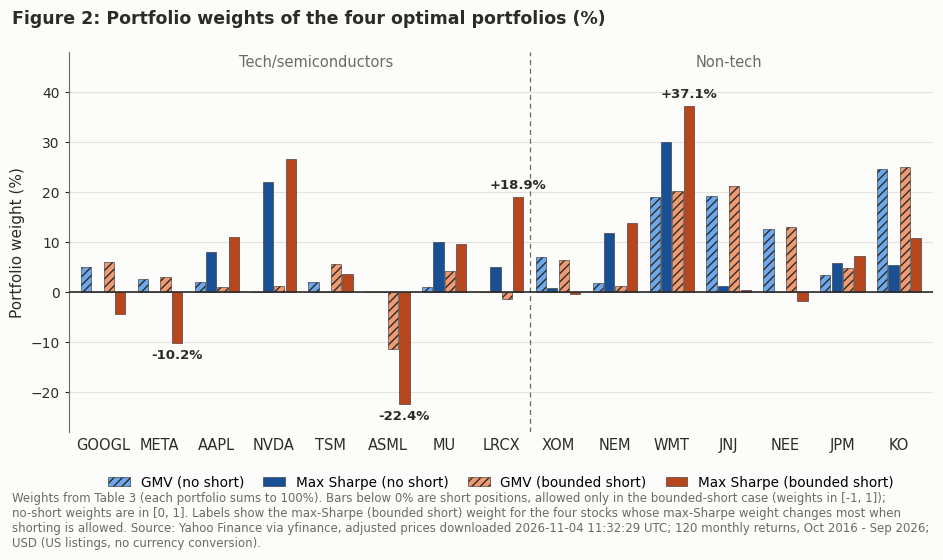

In [53]:
BAR_STYLE = {   # colour family = case (as in Figure 1); light + hatched = GMV, dark + solid = Max Sharpe
    "GMV (no short)":             {"color": "#6da7ec", "hatch": "////"},
    "Max Sharpe (no short)":      {"color": "#184f95", "hatch": None},
    "GMV (bounded short)":        {"color": "#f09a72", "hatch": "////"},
    "Max Sharpe (bounded short)": {"color": "#b8461d", "hatch": None},
}

x = np.arange(len(TICKERS))
bar_w = 0.2                                   # 4 bars x 0.2 = 0.8 of each group's slot
fig, ax = plt.subplots(figsize=(9.5, 5.6))
fig.patch.set_facecolor(SURFACE); ax.set_facecolor(SURFACE)

for k, label in enumerate(PORTFOLIO_LABELS):
    st = BAR_STYLE[label]
    ax.bar(x + (k - 1.5) * bar_w, W[label] * 100, width=bar_w * 0.9,      # 0.9 leaves a small gap between bars
           color=st["color"], hatch=st["hatch"], edgecolor=INK, linewidth=0.4, label=label, zorder=3)

ax.axhline(0, color=INK, lw=1.2, zorder=4)                              # the 0% line: below = short

# Separate the two groups of stocks
k_split = len(TICKERS_TECH) - 0.5
ax.axvline(k_split, color=MUTED, lw=0.9, ls=(0, (4, 3)), zorder=2)
y_top = 47.5                                  # group headings sit above the tallest bar label
ax.text(k_split / 2 - 0.5 + 0.5, y_top, "Tech/semiconductors", ha="center", va="top", fontsize=10.5, color=MUTED)
ax.text((k_split + len(TICKERS)) / 2 - 0.25, y_top, "Non-tech", ha="center", va="top", fontsize=10.5, color=MUTED)

# Selective value labels: the 4 biggest changes between the two max-Sharpe portfolios
ms_change = (W["Max Sharpe (bounded short)"] - W["Max Sharpe (no short)"]).abs().sort_values(ascending=False)
for t in ms_change.index[:4]:
    i, v = TICKERS.index(t), W.at[t, "Max Sharpe (bounded short)"] * 100
    ax.annotate(f"{v:+.1f}%", (i + 1.5 * bar_w, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points",
                ha="center", va="bottom" if v >= 0 else "top", fontsize=9.5, color=INK, fontweight="semibold")

ax.set_xticks(x); ax.set_xticklabels(TICKERS, fontsize=10.5, color=INK)
ax.set_ylabel("Portfolio weight (%)", fontsize=11, color=INK)
ax.set_ylim(-28, 48); ax.set_xlim(-0.6, len(TICKERS) - 0.4)
ax.tick_params(axis="y", labelsize=10, colors=INK, length=3); ax.tick_params(axis="x", length=0)
ax.yaxis.grid(color=GRID, lw=0.8); ax.set_axisbelow(True)
for s in ("top", "right", "bottom"):
    ax.spines[s].set_visible(False)
ax.spines["left"].set_color(MUTED)

ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=4, fontsize=9.8, frameon=False,
          handlelength=1.6, columnspacing=1.4)
fig.suptitle("Figure 2: Portfolio weights of the four optimal portfolios (%)", fontsize=12.5, fontweight="bold",
             color=INK, x=0.02, ha="left", y=0.975)
fig.text(0.02, 0.01, textwrap.fill(
    "Weights from Table 3 (each portfolio sums to 100%). Bars below 0% are short positions, allowed only in the "
    "bounded-short case (weights in [-1, 1]); no-short weights are in [0, 1]. Labels show the max-Sharpe (bounded short) "
    "weight for the four stocks whose max-Sharpe weight changes most when shorting is allowed. "
    f"Source: Yahoo Finance via yfinance, adjusted prices downloaded {DOWNLOAD_UTC}; {N_RETURNS_EXPECTED} monthly returns, "
    f"{period_label}; USD (US listings, no currency conversion).", 150),
    fontsize=8.5, color=MUTED, ha="left", va="bottom")
fig.subplots_adjust(left=0.08, right=0.99, top=0.9, bottom=0.22)

fig.savefig(FIGURES_DIR / "figure2_weights.png", dpi=300, facecolor=SURFACE)
print("Saved outputs/figures/figure2_weights.png (300 dpi)")
plt.show()

**What to check in the output**
- **No blue bar goes below 0%.** The no-short portfolios can't short. Orange bars can.
- **The light hatched bars (GMV)** are tallest for the defensive stocks KO, JNJ, WMT and NEE, as Step 17 found.
- **The dark bars (max-Sharpe)** are tallest for NVDA and WMT.
- **The four labelled stocks** are where the two max-Sharpe portfolios differ most: ASML (large short), LRCX (much larger long), META (short) and WMT (larger long).
- The figure is **optional support material**. Table 3 holds the exact numbers.

## Step 26: What drives the differences between the two max-Sharpe portfolios?

**What this does.** For each stock, compares its weight in *Max Sharpe (no short)* and *Max Sharpe (bounded short)*, sorted by the size of the change, next to the stock's own statistics (mean, SD, return per unit of risk) and two measures of how it relates to the no-short max-Sharpe portfolio $p$:

**Beta of stock $i$ relative to portfolio $p$**: how much the stock moves with the portfolio
$$\beta_{i,p} = \frac{\operatorname{Cov}(R_i, R_p)}{\sigma_p^2} = \frac{(\boldsymbol{\Sigma}\mathbf{w}_p)_i}{\mathbf{w}_p^\top\boldsymbol{\Sigma}\mathbf{w}_p} = \rho_{i,p}\,\frac{\sigma_i}{\sigma_p} \tag{16}$$

**Alpha of stock $i$ relative to portfolio $p$**: excess return beyond what its co-movement with $p$ requires
$$\alpha_{i,p} = (\mu_i - r_f) - \beta_{i,p}\,(\mu_p - r_f) \tag{17}$$

**Why this explains the weights.** At a max-Sharpe portfolio, every stock the optimiser can freely adjust must have $\alpha = 0$. If a stock had $\alpha > 0$, buying a little more would raise the Sharpe ratio; if $\alpha < 0$, selling a little would.
- In the **no-short** portfolio, a stock with **$\alpha < 0$** "wants" a negative weight but cannot have one, so it is stuck at **0%** (a binding bound in Table 3).
- Once shorting is allowed, those stocks are the ones that **go short**. Removing the bound lets their weights move, which in turn changes the weights of the stocks they are correlated with.

$\alpha$ ties the three ingredients together: the stock's **mean** ($\mu_i$), its **SD** ($\sigma_i$) and its **correlation** with the rest of the portfolio ($\rho_{i,p}$, inside $\beta$).

In [54]:
def beta_alpha(w):
    # Equations (16)-(17): each stock's beta and alpha relative to portfolio w
    cov_ip = SIGMA @ w                          # Cov(R_i, R_p) for every stock i
    var_p  = port_variance(w)
    beta   = cov_ip / var_p                     # (16)
    alpha  = (MU - RF_ANNUAL) - beta * (port_return(w) - RF_ANNUAL)   # (17)
    rho    = cov_ip / (np.sqrt(np.diag(SIGMA)) * np.sqrt(var_p))      # correlation of stock with portfolio
    return beta, alpha, rho

w_ns, w_bs = PORTFOLIOS["Max Sharpe (no short)"], PORTFOLIOS["Max Sharpe (bounded short)"]
beta_ns, alpha_ns, rho_ns = beta_alpha(w_ns)
_, alpha_bs, _ = beta_alpha(w_bs)

drivers = pd.DataFrame({
    "w MS no short (%)":      w_ns * 100,
    "w MS bounded (%)":       w_bs * 100,
    "change (pp)":            (w_bs - w_ns) * 100,
    "mean (%)":               MU * 100,
    "SD (%)":                 np.sqrt(np.diag(SIGMA)) * 100,
    "(mean - rf) / SD":       (MU - RF_ANNUAL) / np.sqrt(np.diag(SIGMA)),
    "corr with MS no short":  rho_ns,
    "beta vs MS no short":    beta_ns,
    "alpha vs MS no short (%)": alpha_ns * 100,
    "alpha vs MS bounded (%)":  alpha_bs * 100,
}, index=TICKERS)
drivers = drivers.reindex(drivers["change (pp)"].abs().sort_values(ascending=False).index)

# Checks implied by the theory above
held_ns = w_ns > BOUND_TOL                                       # stocks held (not at the 0% bound)
assert np.allclose(alpha_ns[held_ns], 0, atol=1e-6), "Held stocks should have alpha = 0 at the no-short optimum"
assert (alpha_ns[~held_ns] < 1e-6).all(), "Stocks stuck at 0% should have alpha <= 0"
assert np.allclose(alpha_bs, 0, atol=1e-6), "No bound binds in the bounded case, so every alpha should be 0"
print("Checks passed: held stocks have alpha = 0; stocks at 0% (no short) have alpha < 0; "
      "all alphas = 0 in the bounded portfolio")

drivers.to_csv(TABLES_DIR / "max_sharpe_drivers.csv")          # full precision
print("Saved outputs/tables/max_sharpe_drivers.csv\n")

shorts = drivers[drivers["w MS bounded (%)"] < 0]
print("Shorted in Max Sharpe (bounded short):",
      ", ".join(f"{t} {v:.2f}%" for t, v in shorts["w MS bounded (%)"].items()))
print(f"Total short {w_bs[w_bs < 0].sum():.2%}, total long {w_bs[w_bs > 0].sum():.2%}, "
      f"gross {np.abs(w_bs).sum():.2%}")
print(f"Net weight in Tech/semis: no short {w_ns[:len(TICKERS_TECH)].sum():.1%} -> bounded {w_bs[:len(TICKERS_TECH)].sum():.1%}")
drivers.round(3)                                                 # display only

Checks passed: held stocks have alpha = 0; stocks at 0% (no short) have alpha < 0; all alphas = 0 in the bounded portfolio
Saved outputs/tables/max_sharpe_drivers.csv

Shorted in Max Sharpe (bounded short): ASML -22.38%, META -10.21%, GOOGL -4.39%, NEE -1.78%, XOM -0.29%
Total short -39.05%, total long 139.05%, gross 178.10%
Net weight in Tech/semis: no short 45.2% -> bounded 32.7%


,w MS no short (%),w MS bounded (%),change (pp),mean (%),SD (%),(mean - rf) / SD,corr with MS no short,beta vs MS no short,alpha vs MS no short (%),alpha vs MS bounded (%)
ASML,0.000,-22.378,-22.378,35.133,34.744,0.890,0.716,1.274,-6.260,-0.0
LRCX,5.094,18.904,13.810,45.739,41.751,0.995,0.666,1.423,0.000,-0.0
META,0.000,-10.210,-10.210,24.168,36.416,0.548,0.504,0.940,-7.475,-0.0
WMT,29.916,37.146,7.230,18.246,19.165,0.732,0.490,0.481,-0.000,-0.0
KO,5.429,10.811,5.382,11.583,16.329,0.452,0.302,0.253,-0.000,0.0
NVDA,22.065,26.548,4.483,60.583,46.456,1.213,0.812,1.932,0.000,0.0
GOOGL,0.000,-4.392,-4.392,25.248,26.870,0.783,0.588,0.810,-2.588,0.0
TSM,0.000,3.629,3.629,34.791,32.877,0.930,0.633,1.065,-0.502,0.0
AAPL,8.075,11.081,3.006,29.421,27.130,0.929,0.622,0.864,0.000,-0.0
NEM,11.727,13.845,2.118,18.999,34.294,0.431,0.289,0.507,-0.000,0.0


**What to check in the output**
- **Checks passed.** This is the theory in numbers:
  - stocks held in the no-short portfolio have $\alpha = 0$
  - the five stocks stuck at 0% (GOOGL, META, TSM, ASML, NEE) have $\alpha < 0$
  - in the bounded portfolio every $\alpha = 0$, because no weight is at ±100%
- **The most negative alphas are the main shorts:** META (−7.5%) and ASML (−6.3%), then GOOGL (−2.6%) and NEE (−0.4%).
- **TSM is the exception.** Its $\alpha$ is only slightly negative (−0.5%), and once ASML is shorted, the portfolio's other weights shift enough that TSM ends up slightly *long*. The alphas describe the no-short portfolio, so they show the *direction* each weight wants to move from there, not the final weights.
- The CSV `max_sharpe_drivers.csv` keeps full precision. The display is rounded.

## Step 27: Tech-only vs full 15-stock universe (Table A1, supporting)

**What this does.** Measures how much diversification the 7 non-tech stocks add, using **the same 120 monthly returns, mean vector and covariance matrix** as everything above. This is **support material only**: the required frontiers and Tables 1–3 still use all 15 stocks and are not changed.

The table has three sections:
1. **Average pairwise correlation** (from Step 12's 105 pairs): within the 8 tech stocks (28 pairs), within the 7 non-tech stocks (21 pairs), and between the groups (8 × 7 = 56 pairs).
2. **Equal-weighted portfolios:**
   - 8 tech stocks ($w_i = 1/8$)
   - all 15 stocks ($w_i = 1/15$)
   - 7 non-tech stocks ($w_i = 1/7$), included for reference

   Each row gives the mean (eq. 9), SD (eq. 11) and Sharpe ratio (eq. 12), plus the **average of the individual SDs** and the **SD reduction** (eq. 13): the share of the average stock's risk removed by combining the stocks.
3. **Net weight in tech vs non-tech** in the four Table 3 portfolios: the sum of the weights in each group, so shorts count as negative. Each pair of rows sums to 100%.

Saved at full precision to `outputs/tables/tech_vs_full.csv`. The display is rounded.

In [55]:
rows = []

# ---------- 1. Average pairwise correlations (pairs table from Step 12) ----------
corr_groups = {"Within Tech/semis": "Within tech (8 stocks, 28 pairs)",
               "Within Non-tech":   "Within non-tech (7 stocks, 21 pairs)",
               "Cross-group":       "Between tech and non-tech (56 pairs)"}
for key, name in corr_groups.items():
    rows.append({"Section": "1. Average pairwise correlation", "Item": name,
                 "Measure": "Average correlation", "Value": pairs.loc[pairs["type"] == key, "rho"].mean()})
rows.append({"Section": "1. Average pairwise correlation", "Item": "All 15 stocks (105 pairs)",
             "Measure": "Average correlation", "Value": pairs["rho"].mean()})

# ---------- 2. Equal-weighted portfolios ----------
def equal_weights(tickers):
    # 1/n in each listed stock, 0 elsewhere (vector in TICKERS order, so it works with MU and SIGMA)
    return np.array([1 / len(tickers) if t in tickers else 0.0 for t in TICKERS])

ew_sets = {"EW tech (8 stocks)": TICKERS_TECH, "EW all 15 stocks": TICKERS,
           "EW non-tech (7 stocks, reference)": TICKERS_NONTECH}
ew_summary = {}
for name, tick in ew_sets.items():
    w = equal_weights(tick)
    assert np.isclose(w.sum(), 1.0)
    avg_sd = float(w @ np.sqrt(np.diag(SIGMA)))            # equal-weighted average of the individual SDs
    ew_summary[name] = {"Mean": port_return(w), "SD": port_sd(w), "Sharpe": sharpe(w),
                        "Average individual SD": avg_sd, "SD reduction vs average stock": 1 - port_sd(w) / avg_sd}
    for measure, value in ew_summary[name].items():
        rows.append({"Section": "2. Equal-weighted portfolios", "Item": name, "Measure": measure, "Value": value})

# ---------- 3. Net weight in each group in the four Table 3 portfolios ----------
for label in PORTFOLIO_LABELS:
    w = PORTFOLIOS[label]
    tech, nontech = w[:len(TICKERS_TECH)].sum(), w[len(TICKERS_TECH):].sum()
    assert np.isclose(tech + nontech, 1.0)
    rows.append({"Section": "3. Net weight by group", "Item": label, "Measure": "Tech/semis weight",  "Value": tech})
    rows.append({"Section": "3. Net weight by group", "Item": label, "Measure": "Non-tech weight",    "Value": nontech})

tech_vs_full = pd.DataFrame(rows)
tech_vs_full["Unit"] = np.where(tech_vs_full["Measure"].isin(["Average correlation", "Sharpe"]), "ratio", "decimal (x100 = %)")
tech_vs_full.to_csv(TABLES_DIR / "tech_vs_full.csv", index=False)     # full precision
add_title_and_note("tech_vs_full", "Table A1 (supporting): Tech-only vs full 15-stock universe",
    ["Note: support material only; the required frontiers and Tables 1-3 use all 15 stocks. Values are full precision: "
     "correlations and Sharpe ratios as ratios, other values as decimals (x 100 = %). Group weights are net (shorts negative).",
     SOURCE_NOTE])
print("Saved outputs/tables/tech_vs_full.csv (full precision; title + notes; support material only)\n")

# ---------- Readable displays (rounded for display only) ----------
print("1. Average pairwise correlation")
print(tech_vs_full[tech_vs_full["Section"].str.startswith("1")].set_index("Item")["Value"].round(3).to_string(), "\n")

ew_tbl = pd.DataFrame(ew_summary).T
for c in ["Mean", "SD", "Average individual SD", "SD reduction vs average stock"]:
    ew_tbl[c] = ew_tbl[c] * 100
print("2. Equal-weighted portfolios (%, Sharpe as ratio)")
print(ew_tbl.round({"Mean": 2, "SD": 2, "Sharpe": 3, "Average individual SD": 2, "SD reduction vs average stock": 1}).to_string(), "\n")

grp = (tech_vs_full[tech_vs_full["Section"].str.startswith("3")]
       .pivot(index="Item", columns="Measure", values="Value").loc[PORTFOLIO_LABELS] * 100).round(2)
print("3. Net weight by group (%)")
grp

Saved outputs/tables/tech_vs_full.csv (full precision; title + notes; support material only)

1. Average pairwise correlation
Item
Within tech (8 stocks, 28 pairs)        0.466
Within non-tech (7 stocks, 21 pairs)    0.264
Between tech and non-tech (56 pairs)    0.169
All 15 stocks (105 pairs)               0.267 

2. Equal-weighted portfolios (%, Sharpe as ratio)
                                    Mean     SD  Sharpe  Average individual SD  SD reduction vs average stock
EW tech (8 stocks)                 38.79  27.74   1.247                  37.73                           26.5
EW all 15 stocks                   28.12  18.09   1.322                  30.89                           41.4
EW non-tech (7 stocks, reference)  15.92  13.66   0.857                  23.07                           40.8 

3. Net weight by group (%)


Measure,Non-tech weight,Tech/semis weight
Item,,
GMV (no short),87.46,12.54
Max Sharpe (no short),54.82,45.18
GMV (bounded short),91.79,8.21
Max Sharpe (bounded short),67.31,32.69


**What to check in the output**
- **Section 1:** within-tech correlation (0.47) > within non-tech (0.26) > between groups (0.17). The all-15 average (0.27) matches Step 12.
- **Section 2:**
  - *EW all 15* matches Step 15 exactly (28.12% mean, 18.09% SD, Sharpe 1.32).
  - *EW tech* should have a **higher mean** but a **much higher SD**.
  - Compare the Sharpe ratios, and the **SD reduction** column (how much of the average stock's risk each portfolio removes).
- **Section 3:** each pair of rows sums to 100%. The GMV portfolios are mostly non-tech, and the max-Sharpe portfolios are split between the two groups.
- **Reminder:** this table is supporting evidence only. The required results (Tables 1–3, Figure 1) are unchanged and still use all 15 stocks.

## Step 28: Company table with market capitalisation and 10-year beta (Table 4)

**What this does.** Builds a company overview table with the columns **Company, Ticker, Sector, Country, Market cap (USD bn), 10-year beta**. The internal `group` column is left out of this table (CONFIG still uses it for the Tech/Non-tech blocks elsewhere).

**10-year beta (market beta).** The OLS slope of each stock's 120 monthly simple returns on the market's monthly simple returns over the **same 120 months** (Oct 2016 – Sep 2026):
$$\beta_{i,m} = \frac{\operatorname{Cov}(R_i, R_m)}{\operatorname{Var}(R_m)} \tag{18}$$
- **Market proxy:** the **S&P 500 Total Return index** (`^SP500TR`, Yahoo Finance). It includes reinvested dividends, so it is consistent with the dividend-adjusted stock returns.
- The market's month-end values are built exactly like the stock prices: daily data, last trading day of each month, the same 121 month-ends, and no filling.
- Uses raw (not excess) returns. Because $r_f$ is a constant here, subtracting it would not change the slope.
- β > 1: the stock tends to amplify market moves. β < 1: it dampens them.
- Yahoo's own `beta` field uses 5 years of data, so it differs. The 10-year figure here matches the analysis sample.

**Market capitalisation.** Yahoo Finance's `marketCap`, in USD billions:
- It is a **current snapshot**, taken at the time of retrieval, not a value from the sample period.
- For GOOGL and META it covers **all share classes**, i.e. the whole company.
- For TSM (ADR) and ASML (NY shares) it is Yahoo's USD value of the whole company.

**Fixed data.** As with the prices (Step 4), the index series and the market caps are saved to `data/` on the first run and **reused afterwards**, unless `REDOWNLOAD = True`. That keeps Run All reproducible.

Exported to `outputs/tables/table4_companies.csv` and `.xlsx`, with a numbered title and notes. Market cap is shown to 1 dp and beta to 2 dp (display only).

In [56]:
from datetime import datetime, timezone

MARKET_TICKER = "^SP500TR"                                   # S&P 500 Total Return index (dividends reinvested)
MKT_CSV, CAP_CSV = DATA_DIR / "market_index_daily.csv", DATA_DIR / "market_caps.csv"
MKT_STAMP = DATA_DIR / "market_data_timestamp.txt"

if MKT_CSV.exists() and CAP_CSV.exists() and MKT_STAMP.exists() and not REDOWNLOAD:
    # ---- Reuse the saved market data: the betas and market caps never change on Run All ----
    mkt_daily = pd.read_csv(MKT_CSV, index_col="date", parse_dates=True, float_precision="round_trip")["SP500TR"]
    market_caps = pd.read_csv(CAP_CSV, index_col="ticker", float_precision="round_trip")
    print("REUSED saved market data (set REDOWNLOAD = True in Step 4 to fetch again)")
else:
    # ---- Fresh download: index (same dates as the stock download) + market-cap snapshot ----
    retrieved_utc = datetime.now(timezone.utc)
    raw_mkt = yf.download(MARKET_TICKER, start=DOWNLOAD_START, end=DOWNLOAD_END, interval="1d",
                          auto_adjust=True, actions=False, progress=False)
    close = raw_mkt["Close"]
    mkt_daily = (close.iloc[:, 0] if isinstance(close, pd.DataFrame) else close).rename("SP500TR")
    if mkt_daily.index.tz is not None:
        mkt_daily.index = mkt_daily.index.tz_localize(None)
    mkt_daily.index.name = "date"
    mkt_daily.to_frame().to_csv(MKT_CSV)

    caps = []
    for t in TICKERS:
        info = yf.Ticker(t).info
        caps.append({"ticker": t, "market_cap": info.get("marketCap"), "currency": info.get("currency")})
    market_caps = pd.DataFrame(caps).set_index("ticker")
    market_caps.to_csv(CAP_CSV)
    MKT_STAMP.write_text(f"S&P 500 Total Return index ({MARKET_TICKER}) daily, start={DOWNLOAD_START}, end={DOWNLOAD_END} "
                         f"(exclusive), and market caps (Yahoo 'marketCap') via yfinance {yf.__version__}\n"
                         f"Retrieved (UTC): {retrieved_utc:%Y-%m-%d %H:%M:%S %Z}\n")
    print("NEW market data downloaded and saved to data/")
MKT_RETRIEVED = MKT_STAMP.read_text().splitlines()[1].split(":", 1)[1].strip()
print(MKT_STAMP.read_text())

# ---------- Market month-ends and returns: same construction and checks as the stocks ----------
mkt_monthly = mkt_daily.resample("ME").last().reindex(EXPECTED_MONTH_ENDS)        # no filling
mkt_last_day = mkt_daily.index.to_series().resample("ME").last().reindex(EXPECTED_MONTH_ENDS)
assert mkt_monthly.notna().all() and len(mkt_monthly) == N_PRICES_EXPECTED, "Market index missing a month-end"
assert (mkt_last_day.values == market_last_day.values).all(), "Market month-end dates differ from the stocks'"
mkt_returns = (mkt_monthly / mkt_monthly.shift(1) - 1).iloc[1:]
assert mkt_returns.index.equals(monthly_returns.index), "Market and stock return months must be identical"

# ---------- Equation (18): beta = Cov(R_i, R_m) / Var(R_m), both sample (ddof = 1) ----------
beta_10y = monthly_returns[TICKERS].apply(lambda r: r.cov(mkt_returns) / mkt_returns.var())
slope_check = [np.polyfit(mkt_returns.to_numpy(), monthly_returns[t].to_numpy(), 1)[0] for t in TICKERS]
assert np.allclose(beta_10y.to_numpy(), slope_check, rtol=0, atol=1e-12), "Beta should equal the OLS slope"
assert (market_caps.loc[TICKERS, "currency"] == "USD").all(), "Market caps must be in USD"
print(f"Market (S&P 500 TR): {len(mkt_returns)} monthly returns, mean x12 = {mkt_returns.mean() * 12:.2%}, "
      f"SD x sqrt(12) = {mkt_returns.std() * np.sqrt(12):.2%}")
print("Checks passed: 121 market month-ends on the same trading days as the stocks; beta = OLS slope; caps in USD\n")

# ---------- Table 4 ----------
cfg = CONFIG.set_index("ticker").loc[TICKERS]
table4 = pd.DataFrame({
    "Company":              cfg["company"].to_numpy(),
    "Ticker":               TICKERS,
    "Sector":               cfg["sector"].to_numpy(),
    "Country":              cfg["country"].to_numpy(),
    "Market cap (USD bn)":  market_caps.loc[TICKERS, "market_cap"].to_numpy() / 1e9,
    "10-year beta":         beta_10y.loc[TICKERS].to_numpy(),
})
table4.index = table4.index + 1; table4.index.name = "No."
table4_display = table4.round({"Market cap (USD bn)": 1, "10-year beta": 2})      # display only

table4_display.to_csv(TABLES_DIR / "table4_companies.csv")
with pd.ExcelWriter(TABLES_DIR / "table4_companies.xlsx", engine="openpyxl") as xw:
    table4_display.to_excel(xw, sheet_name="Table 4")
    ws = xw.sheets["Table 4"]
    for col, width in zip("ABCDEFG", (6, 28, 9, 24, 15, 21, 14)):
        ws.column_dimensions[col].width = width
    for c in ws["F"][1:]: c.number_format = "#,##0.0"
    for c in ws["G"][1:]: c.number_format = "0.00"
add_title_and_note("table4_companies",
    "Table 4: The 15 companies: sector, country, market capitalisation and 10-year beta",
    [f"Market cap: Yahoo Finance 'marketCap' via yfinance, USD billions, retrieved {MKT_RETRIEVED} (a current snapshot, "
     "not a sample-period value); GOOGL and META include all share classes; TSM (ADR) and ASML (NY shares) are "
     "Yahoo's USD values for the whole company.",
     "10-year beta: OLS slope of each stock's 120 monthly simple returns (Oct 2016 - Sep 2026) on the monthly returns of "
     "the S&P 500 Total Return index (^SP500TR), beta = Cov(Ri, Rm) / Var(Rm) (eq. 18). Sector = GICS sector; "
     "country = headquarters.",
     SOURCE_NOTE])
table4.to_csv(TABLES_DIR / "table4_companies_full_precision.csv")                   # unrounded copy
print("Saved outputs/tables/table4_companies.csv/.xlsx (title + notes) and table4_companies_full_precision.csv")
table4_display

REUSED saved market data (set REDOWNLOAD = True in Step 4 to fetch again)
S&P 500 Total Return index (^SP500TR) daily, start=2016-08-01, end=2026-10-01 (exclusive), and market caps (Yahoo 'marketCap') via yfinance 1.2.0
Retrieved (UTC): 2026-11-04 12:48:25 UTC

Market (S&P 500 TR): 120 monthly returns, mean x12 = 15.52%, SD x sqrt(12) = 15.36%
Checks passed: 121 market month-ends on the same trading days as the stocks; beta = OLS slope; caps in USD

Saved outputs/tables/table4_companies.csv/.xlsx (title + notes) and table4_companies_full_precision.csv


,Company,Ticker,Sector,Country,Market cap (USD bn),10-year beta
No.,,,,,,
1,Alphabet,GOOGL,Communication Services,United States,3442.7,1.12
2,Meta Platforms,META,Communication Services,United States,1587.9,1.25
3,Apple,AAPL,Information Technology,United States,4823.2,1.15
4,NVIDIA,NVDA,Information Technology,United States,4990.9,1.82
5,Taiwan Semiconductor (ADR),TSM,Information Technology,Taiwan,2099.5,1.15
6,ASML Holding (US listing),ASML,Information Technology,Netherlands,598.2,1.45
7,Micron Technology,MU,Information Technology,United States,967.5,1.75
8,Lam Research,LRCX,Information Technology,United States,288.7,1.56
9,ExxonMobil,XOM,Energy,United States,723.9,0.76


**What to check in the output**
- **REUSED saved market data** on every run after the first, and the retrieval time printed underneath. **Note that time in the report** next to the price download time.
- **Checks passed:**
  - the index has all 121 month-ends, on the same last trading days as the stocks
  - beta equals the OLS regression slope
  - every market cap is in USD
- **Market:** the S&P 500 TR returned about 15.5% a year with about 15.4% SD over the sample. That's a useful benchmark for Table 1.
- **Betas should make economic sense:**
  - **highest:** the chip stocks (NVDA, MU, LRCX, ASML), which are cyclical and amplify market moves
  - **lowest:** the defensives and gold (NEM, NEE, JNJ, KO, WMT)
  - XOM and JPM sit in between
- **Market caps:** mega-caps (AAPL, NVDA, GOOGL) in the trillions, and the smallest companies (NEM, NEE, LRCX) in the low hundreds of billions.